# Première inspection d’un dataset

**Projet / problématique commune :** …

**Dataset :** …

**Responsable :** … · **Relecteur :** …

**Contributeurs :** … · **Date :** …

**Version des données :** …

**Référence du fichier / source :** …

## 1. Situer la source et ouvrir les données

**À faire dans l’ordre :**
1. Identifier la source et consulter la documentation.
2. Préciser la collecte et le périmètre annoncés.
3. Charger les données et vérifier leur lecture.

| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine | INSEE, recensement de la population. Jeu de données « Logement en 2022 – Base infracommunale (IRIS) ». | Page INSEE : insee.fr/fr/statistiques/8647012 |
| Finalité initiale | Statistique publique : décrire le parc de logements et les résidences principales (taille, époque de construction, statut d'occupation, emménagement, chauffage, voitures) à une échelle fine. Rien n'a été produit pour estimer des prix. | Aucun prix ni loyer : la cible du projet n'y figure pas. |
| Mode de collecte | Enquêtes annuelles du recensement : les petites communes sont recensées entièrement une fois tous les 5 ans, les communes de 10 000 habitants ou plus par sondage chaque année. Le millésime « 2022 » combine les enquêtes de 2020 à 2024. | Les effectifs sont des **estimations** (85 % des valeurs ont des décimales), donc peu fiables pour les petits IRIS. |
| Extraction / mise à jour | Publié le 16/10/2025, téléchargé sous forme de `base-ic-logement-2022_csv.zip` (données + dictionnaire `meta_…`). Une base par millésime, mise à jour chaque année. | Le millésime 2022 est le plus récent disponible. Les collectivités d'outre-mer sont dans un fichier séparé, non utilisé ici. |
| Documentation / licence | Dictionnaire des variables fourni (`meta_base-ic-logement-2022.CSV`) : les 101 colonnes y sont toutes décrites. Définitions du recensement sur insee.fr. Réutilisation libre avec mention « Source : Insee ». | Licence non précisée sur la page. Le code `LAB_IRIS` (label de qualité) n'est pas expliqué dans le dictionnaire. |
| Population / objets annoncés | Les IRIS des communes découpées (environ 2 000 habitants chacun) et les communes non découpées, traitées comme un seul IRIS. Fichier : **49 276 lignes**, dont 16 240 IRIS de communes découpées et 33 036 communes entières. | Maille mixte : quartier en ville, commune entière ailleurs. |
| Période / territoire, si pertinents | Recensement 2022 (enquêtes 2020-2024), géographie au 1er janvier 2024. France hors Mayotte : 34 960 communes, 100 départements, dont 971 à 974. | Une seule année. L'Alsace-Moselle est présente (2 149 IRIS) mais absente de DVF+. La géographie 2024 diffère de celle de LOVAC (2026) : quelques communes fusionnées sont à vérifier. |

In [1]:
import numpy as np
import pandas as pd

# ── 1. Chargement ────────────────────────────────────────────────────────────
# sep=";" : séparateur des fichiers INSEE
# dtype : les codes sont lus en texte pour garder les zéros du début ("01001") et la Corse ("2A004")
codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv("../data/base-ic-logement-2022_csv/base-ic-logement-2022.CSV",
                       sep=";", dtype=codes_texte)

# Dictionnaire des variables fourni par l'INSEE avec les données
meta = pd.read_csv("../data/base-ic-logement-2022_csv/meta_base-ic-logement-2022.CSV",
                   sep=";", dtype=str)

# ── 2. La lecture s'est-elle bien passée ? ───────────────────────────────────
# Si le séparateur était faux, on n'aurait qu'une seule colonne
print("Dimensions :", logement.shape)
display(logement.head(3))

# Types : les codes en texte, les effectifs en nombres décimaux
print(logement.dtypes.value_counts())

# Les codes ont-ils gardé leur longueur ? (IRIS = 9 caractères, commune = 5)
print("Longueur des codes IRIS :", logement["IRIS"].str.len().unique())
print("Longueur des codes commune :", logement["COM"].str.len().unique())

# Les accents du dictionnaire sont-ils bien lus ? (sinon : problème d'encodage)
print("Exemple de libellé :", meta["LIB_VAR"].iloc[5])

# ── 3. Toutes les colonnes sont-elles documentées dans le dictionnaire ? ─────
variables_doc = list(meta["COD_VAR"].unique())
non_documentees = []
for c in logement.columns:
    if c not in variables_doc:
        non_documentees.append(c)
print("Variables documentées :", len(variables_doc), "| Colonnes non documentées :", non_documentees)

# ── 4. Population / objets : une ligne = un IRIS ? ───────────────────────────
print("IRIS uniques :", logement["IRIS"].nunique(), "pour", len(logement), "lignes")
non_irisee = logement["IRIS"].str[-4:] == "0000"            # commune non découpée en IRIS
print("Communes non découpées (une seule ligne = la commune) :", non_irisee.sum())
print("IRIS dans des communes découpées :", (~non_irisee).sum())

# ── 5. Période : l'année figure dans le préfixe des noms de colonnes ─────────
print("Préfixes des colonnes :", logement.columns[4:].str[:3].unique())

# ── 6. Territoire ────────────────────────────────────────────────────────────
# Département : 2 caractères en métropole (01, 2A, 68), 3 en outre-mer (971...)
logement["dep"] = np.where(logement["COM"].str[:2] == "97",
                           logement["COM"].str[:3], logement["COM"].str[:2])
print("Communes :", logement["COM"].nunique(), "| Départements :", logement["dep"].nunique())
print("Outre-mer :", sorted(logement[logement["dep"].str[:2] == "97"]["dep"].unique()))
print("Mayotte (976) présente ?", "976" in list(logement["dep"].unique()))
print("IRIS en Alsace-Moselle (57, 67, 68) :", logement["dep"].isin(["57", "67", "68"]).sum())

# ── 7. Cohérence avec les chiffres publiés par l'INSEE (fichier if388) ───────
print("Total logements (millions) :", round(logement["P22_LOG"].sum() / 1e6, 2))

Dimensions : (49276, 101)


,IRIS,COM,TYP_IRIS,LAB_IRIS,P22_LOG,P22_RP,P22_RSECOCC,P22_LOGVAC,P22_MAISON,P22_APPART,...,P22_RP_HABFOR,P22_RP_CASE,P22_RP_MIBOIS,P22_RP_MIDUR,C22_RP_NORME,C22_RP_SOUSOCC_MOD,C22_RP_SOUSOCC_ACC,C22_RP_SOUSOCC_TACC,C22_RP_SUROCC_MOD,C22_RP_SUROCC_ACC
0,010010000,01001,Z,5,379.000000,354.000000,11.000000,14.000000,369.000000,9.000000,...,NaN,NaN,NaN,NaN,9.817143,68.720000,137.440000,137.440000,0.000000,0.0
1,010020000,01002,Z,5,175.000000,121.000000,41.000000,13.000000,173.000000,2.000000,...,NaN,NaN,NaN,NaN,4.963636,9.927273,39.709091,64.527273,0.000000,0.0
2,010040101,01004,H,1,935.984809,835.047694,36.017461,64.919654,408.628548,489.281402,...,NaN,NaN,NaN,NaN,101.267599,223.425915,212.373383,130.053461,35.667175,0.0


float64    97
str         4
Name: count, dtype: int64
Longueur des codes IRIS : [9]
Longueur des codes commune : [5]
Exemple de libellé : Rés secondaires et logts occasionnels en 2022 (princ)
Variables documentées : 101 | Colonnes non documentées : []
IRIS uniques : 49276 pour 49276 lignes
Communes non découpées (une seule ligne = la commune) : 33036
IRIS dans des communes découpées : 16240
Préfixes des colonnes : Index(['P22', 'C22'], dtype='str')
Communes : 34960 | Départements : 100
Outre-mer : ['971', '972', '973', '974']
Mayotte (976) présente ? False
IRIS en Alsace-Moselle (57, 67, 68) : 2149
Total logements (millions) : 37.53


**Constat :**

La base logement 2022 de l'INSEE (recensement, publiée le 16/10/2025) se lit correctement : 49 276 lignes et 101 colonnes, toutes décrites dans le dictionnaire, codes IRIS et commune complets, aucun doublon. Le total de 37,53 millions de logements correspond exactement au chiffre publié par l'INSEE pour 2022. Une ligne est un IRIS en ville, mais la commune entière pour les 33 036 petites communes non découpées. Les effectifs sont des estimations issues des enquêtes 2020-2024. La base ne contient aucun prix et couvre toute la France sauf Mayotte, y compris l'Alsace-Moselle.

**Impact projet :**

La base ne fournit pas la cible, seulement des variables explicatives sur les territoires (vacance, résidences secondaires, profil du parc). DVF+ n'ayant pas de code IRIS, la jointure se fera par le code commune puis par bassin de vie, et le détail par quartier sera perdu. Avec une seule année, ces variables distingueront les territoires entre eux mais n'expliqueront pas l'évolution des prix.

**Action envisagée :**

Toujours lire les codes en texte. Agréger les effectifs par commune puis par bassin de vie (somme des effectifs, puis calcul des taux), joindre avec `codgeo_bv2022` et DVF+ (`l_codinsee`), puis exclure l'Alsace-Moselle. Contrôler le nombre de communes sans correspondance à chaque jointure.

**Incertitudes / limites, si nécessaire :**

- Les petits IRIS ont des effectifs estimés peu fiables : un seuil minimum (50 logements) est nécessaire pour calculer des taux.
- Utiliser le millésime 2022 pour des ventes antérieures introduit une légère anticipation, jugée faible car le parc évolue lentement.
- La géographie (communes au 1er janvier 2024) diffère de celle de LOVAC (2026) : des communes fusionnées pourraient ne pas trouver de correspondance.
- La signification des codes `LAB_IRIS` (label de qualité) n'est pas documentée dans le dictionnaire.
- La licence n'est pas précisée sur la page de l'INSEE.

## 2. Comprendre la structure et une ligne

**À faire dans l’ordre :**
1. Examiner les dimensions, les colonnes et quelques observations.
2. Décrire ce que représente une ligne.
3. Identifier les clés possibles et examiner les répétitions.
4. Contrôler les doublons exacts et distinguer répétitions normales et doublons possibles.

| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 49 276 lignes × 101 colonnes : 4 identifiants en texte (`IRIS`, `COM`, `TYP_IRIS`, `LAB_IRIS`) et 97 effectifs numériques (`P22_…`, `C22_…`). |
| Contenu général, en une phrase | Pour chaque IRIS, le nombre estimé de logements selon leur catégorie (principales, secondaires, vacants), leur type (maison, appartement), leur taille, leur époque de construction, leur statut d'occupation et les caractéristiques des ménages qui les occupent. |
| Unité d’observation | **L'IRIS** : un quartier d'environ 2 000 habitants dans les villes découpées (16 240 lignes), ou **la commune entière** pour les petites communes non découpées (33 036 lignes, code IRIS terminé par `0000`). Paris, Lyon et Marseille sont décrites par **arrondissement** (75101… ; le code 75056 n'existe pas). |
| Identifiants / clés possibles | **`IRIS`** est une clé unique (49 276 valeurs pour 49 276 lignes). **`COM`** n'est pas unique : c'est la clé de regroupement vers la commune, puis le bassin de vie. |
| Une ou plusieurs lignes par objet ? Pourquoi ? | **Une ligne par IRIS.** En revanche, plusieurs lignes par commune pour les 1 924 communes découpées (jusqu'à 153 pour Toulouse, 146 pour Nice, 116 pour Strasbourg ; 26 et plus pour Colmar). C'est normal : il faut additionner les IRIS pour obtenir la commune. Aucune commune ne mélange une ligne « commune entière » et des IRIS. |
| Doublons exacts : nombre / proportion | **0** (0 %). |
| Répétitions métier : règle examinée / résultat | Règle : deux IRIS différents avec exactement les mêmes 97 chiffres. Résultat : 154 lignes, dont **152 IRIS sans aucun logement** (tous les effectifs à 0 : zones d'activité, parcs, IRIS « divers ») et 2 IRIS avec 1 seul logement vacant. Ce sont des **répétitions normales**, pas des doublons : ces lignes seront exclues car elles n'apportent aucune information sur le logement. |

**Si l’unité reste incertaine :** inspecter des cas et consulter la documentation avant d’assimiler lignes et objets.

In [2]:
import pandas as pd

codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv("../data/base-ic-logement-2022_csv/base-ic-logement-2022.CSV",
                       sep=";", dtype=codes_texte)

# ── 1. Dimensions, colonnes et quelques observations ─────────────────────────
print("Lignes :", logement.shape[0], "| Colonnes :", logement.shape[1])
print(list(logement.columns))                        # liste complète des colonnes

# 5 lignes tirées au hasard (random_state : même tirage à chaque exécution)
display(logement.sample(5, random_state=0).iloc[:, :10])

# ── 2. Ce que représente une ligne : exemple d'une commune découpée ──────────
# Colmar (68066) : plusieurs lignes, une par quartier (IRIS)
display(logement[logement["COM"] == "68066"].iloc[:, :8])

# ── 3. Clés possibles ────────────────────────────────────────────────────────
# IRIS : une valeur différente pour chaque ligne ?
print("IRIS uniques :", logement["IRIS"].nunique(), "/", len(logement))

# COM : combien de lignes par commune ?
lignes_par_commune = logement["COM"].value_counts()   # trié du plus grand au plus petit
print("Communes :", len(lignes_par_commune))
print("Communes avec une seule ligne :", (lignes_par_commune == 1).sum())
print("Communes avec plusieurs lignes :", (lignes_par_commune > 1).sum())
print(lignes_par_commune.head(5))                     # communes les plus découpées

# Une commune peut-elle avoir à la fois une ligne "commune entière" (0000) et des IRIS ?
logement["non_irisee"] = logement["IRIS"].str[-4:] == "0000"
melange = logement.groupby("COM")["non_irisee"].nunique()   # 2 = les deux cas dans la même commune
print("Communes mélangeant ligne entière et IRIS :", (melange > 1).sum())

# Paris : codé par arrondissement (75101 à 75120) ou par commune (75056) ?
print("Code 75056 (Paris commune) présent ?", (logement["COM"] == "75056").sum() > 0)
print("Arrondissements parisiens :", logement[logement["COM"].str[:3] == "751"]["COM"].nunique())

# ── 4. Doublons ──────────────────────────────────────────────────────────────
# Doublons exacts : lignes identiques sur toutes les colonnes
nb_doublons = logement.duplicated().sum()
print("Doublons exacts :", nb_doublons, "(", round(nb_doublons / len(logement) * 100, 2), "% )")

# Répétitions métier : deux IRIS différents avec exactement les mêmes chiffres ?
# On compare les 97 colonnes de chiffres, sans les identifiants (colonnes 0 à 3)
colonnes_chiffres = logement.columns[4:101]
repetes = logement[logement.duplicated(subset=colonnes_chiffres, keep=False)]   # keep=False : toutes les lignes concernées
print("Lignes aux chiffres identiques à une autre :", len(repetes))

# Que sont ces lignes ? On regarde combien n'ont aucun logement
print("dont IRIS avec 0 logement :", (repetes["P22_LOG"] == 0).sum())
display(repetes[repetes["P22_LOG"] > 0].iloc[:, :10])          # les autres cas

Lignes : 49276 | Colonnes : 101
['IRIS', 'COM', 'TYP_IRIS', 'LAB_IRIS', 'P22_LOG', 'P22_RP', 'P22_RSECOCC', 'P22_LOGVAC', 'P22_MAISON', 'P22_APPART', 'P22_RP_1P', 'P22_RP_2P', 'P22_RP_3P', 'P22_RP_4P', 'P22_RP_5PP', 'P22_NBPI_RP', 'P22_RPMAISON', 'P22_NBPI_RPMAISON', 'P22_RPAPPART', 'P22_NBPI_RPAPPART', 'P22_RP_M30M2', 'P22_RP_3040M2', 'P22_RP_4060M2', 'P22_RP_6080M2', 'P22_RP_80100M2', 'P22_RP_100120M2', 'P22_RP_120M2P', 'P22_RP_ACHTOT', 'P22_RP_ACH1919', 'P22_RP_ACH1945', 'P22_RP_ACH1970', 'P22_RP_ACH1990', 'P22_RP_ACH2005', 'P22_RP_ACH2019', 'P22_RPMAISON_ACHTOT', 'P22_RPMAISON_ACH1919', 'P22_RPMAISON_ACH1945', 'P22_RPMAISON_ACH1970', 'P22_RPMAISON_ACH1990', 'P22_RPMAISON_ACH2005', 'P22_RPMAISON_ACH2019', 'P22_RPAPPART_ACHTOT', 'P22_RPAPPART_ACH1919', 'P22_RPAPPART_ACH1945', 'P22_RPAPPART_ACH1970', 'P22_RPAPPART_ACH1990', 'P22_RPAPPART_ACH2005', 'P22_RPAPPART_ACH2019', 'P22_MEN', 'P22_MEN_ANEM0002', 'P22_MEN_ANEM0204', 'P22_MEN_ANEM0509', 'P22_MEN_ANEM10P', 'P22_PMEN', 'P22_PMEN_ANE

,IRIS,COM,TYP_IRIS,LAB_IRIS,P22_LOG,P22_RP,P22_RSECOCC,P22_LOGVAC,P22_MAISON,P22_APPART
7064,162220000,16222,Z,5,287.648622,175.498725,61.466770,50.683126,272.973785,9.387197
27042,576050000,57605,Z,5,130.820045,115.224807,3.119048,12.476190,118.390721,12.429324
21620,461050000,46105,Z,5,399.912982,355.524557,39.344286,5.044139,398.927652,0.985330
14721,315554302,31555,H,1,1519.499026,1337.475917,37.063595,144.959514,346.398348,1167.766896
1145,026910209,02691,H,1,1194.004381,990.422808,33.189174,170.392399,764.113433,341.467452


,IRIS,COM,TYP_IRIS,LAB_IRIS,P22_LOG,P22_RP,P22_RSECOCC,P22_LOGVAC
34155,680660101,68066,H,1,1474.008331,1247.810822,123.131943,103.065567
34156,680660102,68066,H,1,2076.010237,1533.149359,338.866530,203.994347
34157,680660103,68066,H,1,1579.008675,1299.293860,138.833497,140.881319
34158,680660104,68066,H,1,1459.006364,953.080129,257.113662,248.812572
34159,680660105,68066,H,1,1892.010252,1535.425654,99.880076,256.704522
34160,680660201,68066,H,1,1034.505973,894.655327,33.984074,105.866572
34161,680660202,68066,H,1,1298.007085,1061.133139,147.249345,89.624600
34162,680660301,68066,H,1,3774.024051,3602.180974,70.566592,101.276485
34163,680660401,68066,H,1,1712.010876,1628.844328,24.033655,59.132893
34164,680660402,68066,H,1,2137.512756,1910.424655,145.114230,81.973871


IRIS uniques : 49276 / 49276
Communes : 34960
Communes avec une seule ligne : 33036
Communes avec plusieurs lignes : 1924
COM
31555    153
06088    146
67482    116
59350    110
44109     97
Name: count, dtype: int64
Communes mélangeant ligne entière et IRIS : 0
Code 75056 (Paris commune) présent ? False
Arrondissements parisiens : 20
Doublons exacts : 0 ( 0.0 % )
Lignes aux chiffres identiques à une autre : 154
dont IRIS avec 0 logement : 152


,IRIS,COM,TYP_IRIS,LAB_IRIS,P22_LOG,P22_RP,P22_RSECOCC,P22_LOGVAC,P22_MAISON,P22_APPART
18159,381930104,38193,A,3,1.0,0.0,0.0,1.0,1.0,0.0
25579,551390000,55139,Z,5,1.0,0.0,0.0,1.0,1.0,0.0


**Constat :**

Une ligne correspond à un IRIS : le code `IRIS` est unique et il n'y a aucun doublon exact. L'unité n'est pas homogène : quartier d'environ 2 000 habitants dans les 1 924 communes découpées (jusqu'à 153 lignes pour Toulouse), commune entière pour les 33 036 autres. Paris, Lyon et Marseille sont décrites par arrondissement (75101…), sans ligne pour la commune (75056). Les 154 lignes aux chiffres identiques ne sont pas des doublons : ce sont 152 IRIS sans aucun logement (zones d'activité, IRIS « divers ») et 2 IRIS avec un seul logement.

**Impact projet :**

Les lignes ne sont pas directement comparables : un IRIS urbain et une commune rurale entière n'ont pas la même taille. Pour rapprocher cette base des autres sources, qui sont à la commune, il faudra additionner les IRIS de chaque commune. Le codage par arrondissement de Paris, Lyon et Marseille peut faire échouer ces rapprochements si l'autre source utilise le code de la commune entière (75056, 69123, 13055), alors que ces trois villes représentent une part importante des ventes.

**Action envisagée :**

Supprimer les 152 IRIS sans logement. Agréger les effectifs par commune avec un `groupby("COM").sum()`, puis recalculer les taux. Selon le codage des autres sources, regrouper les arrondissements dans leur commune (751xx → 75056, 6938x → 69123, 132xx → 13055). Vérifier après agrégation qu'il y a bien une ligne par commune.

**Incertitudes / limites, si nécessaire :**

- L'agrégation à la commune fait perdre les écarts entre quartiers d'une même ville (centre et périphérie de Toulouse, par exemple), alors qu'ils comptent beaucoup pour les prix.


## 3. Comprendre les variables

**À faire dans l’ordre :**
1. Identifier le sens et les unités des variables.
2. Distinguer nature statistique et type de stockage.
3. Examiner modalités et plages de valeurs pour vérifier cette compréhension.
4. Repérer les variables ambiguës ou constantes et leur utilité éventuelle.

| Variable | Signification | Nature statistique | Unité / modalités | Type de stockage et cohérence |
|---|---|---|---|---|
| `IRIS` | Code IRIS : département + commune (ou arrondissement) + numéro d'IRIS | Qualitative nominale (identifiant) | Code à 9 caractères ; 49 276 valeurs | str : cohérent (lu en texte volontairement) |
| `COM` | Code commune, ou arrondissement pour Paris, Lyon, Marseille | Qualitative nominale (identifiant) | Code à 5 caractères ; 34 960 valeurs | str : cohérent |
| `TYP_IRIS` | Type d'IRIS : habitat (H), activité (A), divers (D), commune non découpée (Z) | Qualitative nominale | H / A / D / Z | str : cohérent |
| `LAB_IRIS` | Label de qualité de l'IRIS | Qualitative nominale (ordinale ?) | 1 / 2 / 3 / 4 / 5 / Z (5 = toutes les communes non découpées) | str : cohérent, mais **codes non expliqués** |
| `P22_LOG` | Nombre total de logements | Quantitative continue (effectif estimé) | Logements ; de 0 à 29 617 | float64 : cohérent (décimales dues au sondage) |
| `P22_RP`, `P22_RSECOCC`, `P22_LOGVAC` | Résidences principales, secondaires et occasionnelles, vacantes | Quantitative continue | Logements ; de 0 à 26 565 | float64 : cohérent ; leur somme = `P22_LOG` |
| `P22_MAISON`, `P22_APPART` | Maisons, appartements (tous logements) | Quantitative continue | Logements ; de 0 à 25 844 | float64 : cohérent |
| `P22_RP_1P` à `P22_RP_5PP` | Résidences principales de 1, 2, 3, 4, 5 pièces ou plus | Quantitative continue | Logements ; de 0 à 3 435 | float64 : cohérent ; somme = `P22_RP` |
| `P22_RP_M30M2` à `P22_RP_120M2P` | Résidences principales par tranche de surface (< 30 m² à ≥ 120 m²) | Quantitative continue | Logements ; de 0 à 3 614 | float64 : cohérent ; somme = `P22_RP` |
| `P22_RPMAISON`, `P22_RPAPPART` | Résidences principales de type maison, appartement | Quantitative continue | Logements | float64 : cohérent |
| `P22_NBPI_RP` (+ maison, appart, par ancienneté) | **Total** des pièces des résidences principales | Quantitative continue (somme) | Pièces ; de 0 à 19 326 | float64 : cohérent ; divisé par `P22_RP`, donne 4,0 pièces en moyenne |
| `P22_RP_ACHTOT` à `P22_RP_ACH2019` (+ maison, appart) | Résidences principales par époque d'achèvement (avant 1919 … 2006-2019) ; `ACHTOT` = achevées avant 2020 | Quantitative continue | Logements | float64 : cohérent ; `ACHTOT` = 98,3 % de `P22_RP` (sans les constructions récentes) |
| `P22_MEN`, `P22_MEN_ANEM…` | Ménages, par ancienneté d'emménagement (< 2 ans, 2-4, 5-9, 10 ans et plus) | Quantitative continue | Ménages | float64 : cohérent ; `P22_MEN` = `P22_RP` (1 ménage = 1 résidence principale) |
| `P22_PMEN`, `P22_PMEN_ANEM…` | Population des ménages, par ancienneté d'emménagement | Quantitative continue (somme) | Personnes ; de 0 à 15 674 | float64 : cohérent |
| `P22_NBPI_RP_ANEM…` | Total des pièces selon l'ancienneté d'emménagement | Quantitative continue (somme) | Pièces | float64 : cohérent |
| `P22_RP_PROP`, `_LOC`, `_LOCHLMV`, `_GRAT` | Résidences principales occupées par propriétaire, locataire (dont HLM loué vide), logé gratuitement | Quantitative continue | Logements | float64 : cohérent ; propriétaires + locataires + gratuits = `P22_RP` (HLM inclus dans les locataires) |
| `P22_NPER_RP…` | Nombre de personnes, selon le statut d'occupation | Quantitative continue (somme) | Personnes | float64 : cohérent |
| `P22_ANEM_RP…` | **Total** des années d'ancienneté d'emménagement, selon le statut | Quantitative continue (somme) | Années ; de 0 à 69 414 | float64 : cohérent ; divisé par `P22_RP`, donne 15,3 ans en moyenne |
| `P22_RP_CGAZV`, `_CFIOUL`, `_CELEC`, `_CGAZB`, `_CAUT` | Résidences principales par combustible de chauffage (gaz de ville, fioul, électricité, gaz en bouteille, autre) | Quantitative continue | Logements | float64 : cohérent ; **1,4 % manquants = outre-mer** (non renseigné) |
| `P22_RP_ELEC`, `_EAUCH`, `_BDWC`, `_CHOS`, `_CLIM`, `_TTEGOU`, `_HABFOR`, `_CASE`, `_MIBOIS`, `_MIDUR` | Équipements et type de bâti spécifiques aux départements d'outre-mer | Quantitative continue | Logements | float64 : cohérent ; **98,6 % manquants = métropole** (non concernée) |
| `P22_RP_GARL`, `_VOIT1P`, `_VOIT1`, `_VOIT2P` | Ménages avec au moins un parking, au moins une voiture, une voiture, deux ou plus | Quantitative continue | Ménages | float64 : cohérent |
| `C22_RP_NORME` à `C22_RP_SUROCC_ACC` | Résidences principales selon l'occupation (normale, sous-occupation, suroccupation), exploitation complémentaire | Quantitative continue | Logements | float64 : cohérent ; somme ≈ `P22_RP` (100,1 %) |

**Variables ambiguës / documentation manquante :** `LAB_IRIS` (label de qualité) a des codes 1 à 5 et Z non expliqués dans le dictionnaire. Les variables `NBPI`, `NPER`, `PMEN` et `ANEM_RP` sont des **totaux**, pas des moyennes : il faut les diviser par le nombre de résidences principales. `ACHTOT` ne signifie pas « total » mais « achevées avant 2020 ». `P22_RP_GARL` concerne les ménages malgré son nom en « RP ». Le préfixe `C22_` (exploitation complémentaire) suit une méthode légèrement différente de `P22_` (exploitation principale). Aucune variable constante, aucune valeur négative.

**Utilité provisoire pour le projet :** utiles une fois converties en **parts** : taux de vacance, part de résidences secondaires, part de maisons, part de propriétaires, part de HLM, part de logements anciens (avant 1946) ou récents, surface et nombre de pièces moyens, ancienneté moyenne d'emménagement et part d'emménagés récents (mobilité résidentielle), suroccupation. Peu utiles : les variables propres à l'outre-mer et le détail du chauffage. Les nombreuses déclinaisons (maison ou appartement × époque, ancienneté × pièces…) sont redondantes : en garder quelques-unes.

**Si prédiction : disponibilité au moment de prédire / risques de fuite à examiner :** aucune variable n'est calculée à partir des prix, donc pas de fuite directe. En revanche, le recensement 2022 (enquêtes 2020-2024) n'a été publié qu'en octobre 2025 : pour des ventes antérieures, ces informations n'étaient pas encore disponibles (légère anticipation). Les ménages emménagés depuis moins de 2 ans reflètent les déménagements, donc en partie les ventes, des mêmes années que les prix étudiés : ce n'est pas une fuite de la cible, mais une information contemporaine à surveiller.

In [3]:
import pandas as pd
from pandas.api.types import is_numeric_dtype

codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv("../data/base-ic-logement-2022_csv/base-ic-logement-2022.CSV",
                       sep=";", dtype=codes_texte)

# ── 1. Sens des variables : on le prend dans le dictionnaire INSEE ───────────
meta = pd.read_csv("../data/base-ic-logement-2022_csv/meta_base-ic-logement-2022.CSV",
                   sep=";", dtype=str)
meta = meta.drop_duplicates("COD_VAR").set_index("COD_VAR")    # une ligne par variable


# ── 2. Nature statistique et unité : déduites du nom de la variable ─────────
def nature_unite(col):
    if col in ["IRIS", "COM"]:
        return "qualitative nominale (identifiant)", "code"
    if col in ["TYP_IRIS", "LAB_IRIS"]:
        return "qualitative nominale", "modalités"
    if "NBPI" in col:                       # somme des pièces de tous les logements
        return "quantitative continue (total)", "pièces"
    if "NPER" in col or "PMEN" in col:      # somme des personnes
        return "quantitative continue (total)", "personnes"
    if "ANEM_RP" in col:                    # somme des années d'ancienneté d'emménagement
        return "quantitative continue (total)", "années"
    if "_MEN" in col:
        return "quantitative continue (effectif estimé)", "ménages"
    return "quantitative continue (effectif estimé)", "logements"


# ── 3. Modalités ou plage de valeurs ────────────────────────────────────────
def modalites(col):
    s = logement[col].dropna()                             # on ignore les valeurs manquantes
    if is_numeric_dtype(logement[col]):
        return "de " + str(round(s.min(), 1)) + " à " + str(round(s.max(), 1))
    if s.nunique() <= 6:
        return str(sorted(s.unique()))                     # peu de modalités : on les liste
    return str(s.nunique()) + " valeurs"                   # sinon : on les compte


# ── 4. Type de stockage et cohérence avec la nature ─────────────────────────
def coherence(col, nature):
    dtype = str(logement[col].dtype)
    manquants = round(logement[col].isna().mean() * 100, 1)
    texte = dtype + " : cohérent"
    if nature.startswith("quantitative") and not is_numeric_dtype(logement[col]):
        texte = dtype + " : incohérent"                    # un nombre stocké en texte
    if manquants > 0:
        texte = texte + " (" + str(manquants) + " % manquants)"
    return texte


# ── 5. Assemblage du tableau (une ligne par variable) ───────────────────────
lignes = []
for col in logement.columns:
    nature, unite = nature_unite(col)
    lignes.append({"Variable": col,
                   "Signification": meta.loc[col, "LIB_VAR_LONG"],   # libellé long de l'INSEE
                   "Nature statistique": nature,
                   "Unité / modalités": unite + " ; " + modalites(col),
                   "Type de stockage et cohérence": coherence(col, nature)})
tableau = pd.DataFrame(lignes).set_index("Variable")
pd.set_option("display.max_colwidth", None)                # ne pas couper le texte
display(tableau)


# ── 6. Variables constantes, valeurs négatives, modalités de LAB_IRIS ───────
constantes = []
for col in logement.columns:
    if logement[col].nunique() <= 1:
        constantes.append(col)
print("Variables constantes :", constantes)
print("Valeurs négatives :", (logement.select_dtypes("number") < 0).sum().sum())
print(logement["LAB_IRIS"].value_counts())


# ── 7. Vérifier notre compréhension par des sommes ──────────────────────────
# Si on a bien compris, ces sous-catégories doivent redonner le total des résidences principales
rp = logement["P22_RP"].sum()
pieces = logement[["P22_RP_1P", "P22_RP_2P", "P22_RP_3P", "P22_RP_4P", "P22_RP_5PP"]].sum().sum()
statut = logement[["P22_RP_PROP", "P22_RP_LOC", "P22_RP_GRAT"]].sum().sum()
occupation = logement[["C22_RP_NORME", "C22_RP_SOUSOCC_MOD", "C22_RP_SOUSOCC_ACC",
                       "C22_RP_SOUSOCC_TACC", "C22_RP_SUROCC_MOD", "C22_RP_SUROCC_ACC"]].sum().sum()
print("Pièces (1 à 5+) / RP :", round(pieces / rp, 3))
print("Propriétaires + locataires + gratuits / RP :", round(statut / rp, 3))
print("Classes d'occupation C22 / RP :", round(occupation / rp, 3))
print("Ménages = résidences principales ? écarts :", (abs(logement["P22_MEN"] - logement["P22_RP"]) > 0.5).sum())
print("Construites avant 2020 (ACHTOT) / RP :", round(logement["P22_RP_ACHTOT"].sum() / rp, 3))

# Les variables "NBPI" et "ANEM" sont des totaux : divisées par RP, elles donnent une moyenne
print("Nombre moyen de pièces par résidence principale :", round(logement["P22_NBPI_RP"].sum() / rp, 1))
print("Ancienneté moyenne d'emménagement (années) :", round(logement["P22_ANEM_RP"].sum() / rp, 1))

,Signification,Nature statistique,Unité / modalités,Type de stockage et cohérence
Variable,,,,
IRIS,Code du département suivi du numéro de commune ou du numéro d'arrondissement municipal suivi du numéro d'IRIS,qualitative nominale (identifiant),code ; 49276 valeurs,str : cohérent
COM,Code du département suivi du numéro de commune ou du numéro d'arrondissement municipal pour Paris Lyon et Marseille,qualitative nominale (identifiant),code ; 34960 valeurs,str : cohérent
TYP_IRIS,"Type d'Iris : habitat (H), activité (A), divers (D), Autre (Z)",qualitative nominale,"modalités ; ['A', 'D', 'H', 'Z']",str : cohérent
LAB_IRIS,Label de qualité de l'Iris,qualitative nominale,"modalités ; ['1', '2', '3', '4', '5', 'Z']",str : cohérent
P22_LOG,Nombre de logements,quantitative continue (effectif estimé),logements ; de 0.0 à 29617.5,float64 : cohérent
...,...,...,...,...
C22_RP_SOUSOCC_MOD,Résidences principales en sous-occupation modérée,quantitative continue (effectif estimé),logements ; de 0.0 à 1874.1,float64 : cohérent
C22_RP_SOUSOCC_ACC,Résidences principales en sous-occupation accentuée,quantitative continue (effectif estimé),logements ; de 0.0 à 1235.9,float64 : cohérent
C22_RP_SOUSOCC_TACC,Résidences principales en sous-occupation très accentuée,quantitative continue (effectif estimé),logements ; de 0.0 à 1559.4,float64 : cohérent


Variables constantes : []
Valeurs négatives : 0
LAB_IRIS
5    33036
1    10319
4     2517
2     1641
3     1149
Z      614
Name: count, dtype: int64
Pièces (1 à 5+) / RP : 1.0
Propriétaires + locataires + gratuits / RP : 1.0
Classes d'occupation C22 / RP : 1.001
Ménages = résidences principales ? écarts : 0
Construites avant 2020 (ACHTOT) / RP : 0.983
Nombre moyen de pièces par résidence principale : 4.0
Ancienneté moyenne d'emménagement (années) : 15.3


**Constat :**

Les 101 variables sont toutes documentées : 4 codes stockés en texte et 97 effectifs numériques (float64), cohérents avec leur nature. Aucune variable n'est constante et aucune valeur n'est négative. Les sous-catégories redonnent bien les totaux (pièces, statut d'occupation et classes d'occupation = résidences principales ; ménages = résidences principales). Les valeurs manquantes sont structurelles : les variables propres à l'outre-mer sont vides en métropole (98,6 %), celles du chauffage en outre-mer (1,4 %). Certaines variables sont des totaux (pièces, personnes, années d'emménagement) et non des moyennes. Les effectifs dépendent de la taille de l'IRIS, de 0 à près de 30 000 logements.

**Impact projet :**

Les effectifs bruts ne sont pas comparables entre territoires : un grand IRIS a mécaniquement plus de logements vacants qu'un petit. Il faut les transformer en parts (taux de vacance, part de résidences secondaires, de maisons, de propriétaires, de HLM, de logements anciens) et en moyennes (pièces par logement, ancienneté d'emménagement), qui décrivent le profil des territoires. Les nombreuses déclinaisons d'une même information sont redondantes et risquent de gêner les modèles linéaires.

**Action envisagée :**

Calculer une dizaine d'indicateurs en parts ou en moyennes après agrégation à la commune, en divisant par le bon dénominateur (logements totaux ou résidences principales). Écarter les variables propres à l'outre-mer et le détail croisé (maison ou appartement × époque, ancienneté × pièces). Vérifier ensuite les corrélations entre indicateurs pour éliminer les doublons d'information.

**Incertitudes / limites, si nécessaire :**

- Les codes de `LAB_IRIS` ne sont pas expliqués dans le dictionnaire : la variable n'est pas exploitée tant qu'on n'a pas trouvé sa signification dans la documentation de l'INSEE.
- Les variables `C22_` suivent une exploitation complémentaire, avec un léger écart (0,1 %) par rapport aux variables `P22_`.
- Le recensement 2022 n'a été publié qu'en octobre 2025 : l'utiliser pour des ventes antérieures revient à exploiter une information qui n'était pas encore disponible.

## 4. Vérifier le périmètre réel

**À faire dans l’ordre :**
1. Décrire les populations, objets et groupes présents.
2. Examiner période et territoire si ces dimensions existent.
3. Comparer les effectifs entre subdivisions pertinentes.
4. Repérer trous, ruptures, exclusions et écarts au périmètre annoncé.

| Dimension | Couverture observée | Effectifs / preuve | Écart / limite |
|---|---|---|---|
| Population / objets / groupes | Tous les logements (37,53 millions), répartis en IRIS d'habitat (H), d'activité (A), divers (D) et en communes non découpées (Z). | H : 15 010 lignes, 58,2 % des logements ; Z : 33 036 lignes, 40,7 % ; A : 829 lignes, 0,7 % ; D : 401 lignes, 0,3 %. 152 IRIS sans aucun logement. | Le nombre de lignes ne reflète pas le poids réel : les communes non découpées font 67 % des lignes mais seulement 41 % des logements. Une statistique calculée « par ligne » donnerait trop de poids au rural. |
| Temps, si pertinent | Une seule année : recensement 2022 (préfixes `P22_` et `C22_` uniquement). | Aucune colonne de date ; les enquêtes couvrent 2020-2024. | Aucune évolution observable. Pour les ventes avant 2022, l'information est postérieure (anticipation) ; pour 2023-2025, elle date de plusieurs années. |
| Géographie, si pertinente | France hors Mayotte : 100 départements (96 en métropole, 971 à 974), 34 960 communes. Paris, Lyon et Marseille sont découpées en 20, 9 et 16 arrondissements. | Total de 37,53 millions de logements, contre 37,52 millions publiés par l'INSEE pour 2022 (if388) : la couverture est complète. Outre-mer : 707 lignes, 0,96 million de logements. | Mayotte est absente (comme annoncé). L'Alsace-Moselle est présente : 2 149 IRIS, 1,52 million de logements (4,0 %), mais ces territoires ne pourront pas être reliés aux ventes DVF+. |
| Autre dimension : taille des départements | Effectifs très inégaux entre départements. | De 62 201 logements (Lozère) à 1 399 122 (Paris) ; médiane de 301 756. | Ces écarts reflètent la population réelle (le total correspond au chiffre INSEE) : ce n'est **pas** une sous-représentation. Mais les taux des petits départements reposent sur moins d'IRIS et sont plus fragiles. |

Un faible effectif ne prouve pas une sous-représentation : préciser le point de comparaison.

In [4]:
import numpy as np
import pandas as pd

codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv("../data/base-ic-logement-2022_csv/base-ic-logement-2022.CSV",
                       sep=";", dtype=codes_texte)

# Colonnes utiles pour décrire le périmètre
# Département : 2 caractères en métropole (01, 2A, 68), 3 en outre-mer (971...)
logement["dep"] = np.where(logement["COM"].str[:2] == "97",
                           logement["COM"].str[:3], logement["COM"].str[:2])
logement["non_irisee"] = logement["IRIS"].str[-4:] == "0000"   # commune non découpée
logement["outre_mer"] = logement["dep"].str[:2] == "97"

# ── 1. Objets et groupes présents ────────────────────────────────────────────
# Types d'IRIS : nombre de lignes ET nombre de logements dans chaque type
groupes = logement.groupby("TYP_IRIS").agg(nb_lignes=("IRIS", "count"),
                                           logements=("P22_LOG", "sum"))
groupes["logements"] = groupes["logements"].round(0)
groupes["% logements"] = (groupes["logements"] / groupes["logements"].sum() * 100).round(1)
display(groupes)

# Communes découpées (villes) ou non : part des lignes et part des logements
taille = logement.groupby("non_irisee").agg(nb_lignes=("IRIS", "count"),
                                            logements=("P22_LOG", "sum"))
taille["% logements"] = (taille["logements"] / taille["logements"].sum() * 100).round(1)
display(taille)

# Lignes sans aucun logement
print("IRIS sans logement :", (logement["P22_LOG"] == 0).sum())

# ── 2. Temps : une seule année dans le nom des colonnes ──────────────────────
# (colonnes 4 à 100 : les 97 effectifs, sans les colonnes ajoutées plus haut)
print("Préfixes d'année :", logement.columns[4:101].str[:3].unique())

# ── 3. Territoire ────────────────────────────────────────────────────────────
print("Départements :", logement["dep"].nunique(), "| Communes :", logement["COM"].nunique())
print("Mayotte (976) présente ?", "976" in list(logement["dep"].unique()))

# Arrondissements de Paris (751..), Lyon (6938.) et Marseille (132..)
arr_paris = logement[logement["COM"].str[:3] == "751"]["COM"].nunique()
arr_lyon = logement[logement["COM"].str[:4] == "6938"]["COM"].nunique()
arr_marseille = logement[logement["COM"].str[:3] == "132"]["COM"].nunique()
print("Arrondissements Paris / Lyon / Marseille :", arr_paris, arr_lyon, arr_marseille)

# Métropole / outre-mer : nombre de lignes et de logements
print(logement.groupby("outre_mer")["P22_LOG"].agg(["count", "sum"]))

# Alsace-Moselle (absente de DVF+)
am = logement[logement["dep"].isin(["57", "67", "68"])]
print("Alsace-Moselle :", len(am), "IRIS,", round(am["P22_LOG"].sum() / 1e6, 2), "million de logements,",
      round(am["P22_LOG"].sum() / logement["P22_LOG"].sum() * 100, 1), "% du total")

# ── 4. Comparer les effectifs entre départements ────────────────────────────
par_dep = logement.groupby("dep").agg(nb_lignes=("IRIS", "count"),
                                      logements=("P22_LOG", "sum"))
par_dep = par_dep.sort_values("logements")
print(par_dep.head(3))       # départements avec le moins de logements
print(par_dep.tail(3))       # départements avec le plus de logements
print(par_dep["logements"].describe().round(0))

# ── 5. Point de comparaison externe : total publié par l'INSEE ──────────────
# if388 (figure 2) : 24 023 milliers de logements en 1982, indice 156,2 en 2022
publie_2022 = 24023 * 156.2 / 100 / 1000          # en millions
print("Total du fichier :", round(logement["P22_LOG"].sum() / 1e6, 2), "millions")
print("Total publié par l'INSEE pour 2022 :", round(publie_2022, 2), "millions")

,nb_lignes,logements,% logements
TYP_IRIS,,,
A,829,270553.0,0.7
D,401,125883.0,0.3
H,15010,21856015.0,58.2
Z,33036,15275429.0,40.7


,nb_lignes,logements,% logements
non_irisee,,,
False,16240,2.225245e+07,59.3
True,33036,1.527543e+07,40.7


IRIS sans logement : 152
Préfixes d'année : Index(['P22', 'C22'], dtype='str')
Départements : 100 | Communes : 34960
Mayotte (976) présente ? False
Arrondissements Paris / Lyon / Marseille : 20 9 16
           count           sum
outre_mer                     
False      48569  3.656898e+07
True         707  9.588988e+05
Alsace-Moselle : 2149 IRIS, 1.52 million de logements, 4.0 % du total
     nb_lignes     logements
dep                         
48         158  62200.979516
90         123  73832.026585
23         262  89302.207320
     nb_lignes     logements
dep                         
13         840  1.078388e+06
59        1346  1.262771e+06
75         992  1.399122e+06
count        100.0
mean      375279.0
std       268803.0
min        62201.0
25%       168184.0
50%       301756.0
75%       498921.0
max      1399122.0
Name: logements, dtype: float64
Total du fichier : 37.53 millions
Total publié par l'INSEE pour 2022 : 37.52 millions


**Constat :**

La couverture est complète sur le périmètre annoncé : 37,53 millions de logements, contre 37,52 millions publiés par l'INSEE pour 2022. Elle porte sur 100 départements (dont 4 d'outre-mer) et 34 960 communes, sans Mayotte. Le nombre de lignes ne reflète pas le poids réel : les communes non découpées représentent 67 % des lignes mais 41 % des logements, et 152 IRIS ne contiennent aucun logement. Les départements vont de 62 201 logements (Lozère) à 1 399 122 (Paris), ce qui correspond à leur population réelle et non à une sous-représentation. L'Alsace-Moselle est présente (1,52 million de logements, 4 %). Il n'y a qu'une seule année (recensement 2022).

**Impact projet :**

Toute statistique calculée « par ligne » (moyenne des taux des IRIS, par exemple) donnerait trop de poids aux petites communes rurales : il faut raisonner en logements, en additionnant les effectifs avant de calculer les taux. L'Alsace-Moselle, sans ventes dans DVF+, ne servira pas pour la modélisation. Avec une seule année, la base décrit les différences entre territoires, pas leur évolution.

**Action envisagée :**

Supprimer les 152 IRIS sans logement. Calculer les taux à partir de sommes d'effectifs (par commune ou par département), jamais par moyenne de taux. Exclure l'Alsace-Moselle au moment de la jointure avec les ventes, et ne garder l'outre-mer que si DVF+ le couvre.

**Incertitudes / limites, si nécessaire :**

- Les taux des petits départements et des petites communes reposent sur peu de logements estimés, donc plus fragiles.
- Le millésime unique (enquêtes 2020-2024) ne correspond exactement à aucune année de vente : il anticipe les ventes antérieures et vieillit pour les ventes de 2024-2025.

## 5. Repérer et investiguer les problèmes de qualité

### 5.1 Valeurs manquantes

1. Mesurer les absences par variable et rechercher les codes qui peuvent les masquer.
2. Vérifier leur sens : inconnue, non applicable, absence attendue ou autre.
3. Pour les absences inexpliquées importantes, examiner leur concentration par groupe, période ou autre variable pertinente.
4. Formuler une hypothèse de mécanisme uniquement si les éléments le permettent.

| Variable | Nombre / proportion | Codes d’absence possibles | Sens / structure observée |
|---|---|---|---|
| 10 variables propres à l'outre-mer : `P22_RP_ELEC`, `_EAUCH`, `_BDWC`, `_CHOS`, `_CLIM`, `_TTEGOU`, `_HABFOR`, `_CASE`, `_MIBOIS`, `_MIDUR` | 48 569 chacune (98,6 %) | NaN uniquement | **Non applicable** : 100 % manquantes en métropole, 0 % en outre-mer. Le dictionnaire les décrit comme « variable spécifique aux départements d'outre-mer ». Absence attendue. |
| 5 variables de combustible de chauffage : `P22_RP_CGAZV`, `_CFIOUL`, `_CELEC`, `_CGAZB`, `_CAUT` | 707 chacune (1,4 %) | NaN uniquement | **Non applicable / non collecté** : 100 % manquantes en outre-mer, 0 % en métropole. Absence attendue (le chauffage n'est pas demandé dans les DOM). |
| Les 86 autres variables | 0 (0 %) | Aucun texte vide, aucune valeur négative. Un seul « 9999 » (`P22_NBPI_RP`, IRIS 956520000), plausible : 4,4 pièces par résidence principale. | Aucune absence. |
| Zéros dans les effectifs (`P22_LOGVAC` : 1,9 % ; `P22_RSECOCC` : 3,9 %) | 1,9 % à 3,9 % des IRIS | Le zéro pourrait masquer une absence | **Vrais zéros** : 78,7 % des IRIS sans logement vacant ont moins de 100 logements (médiane de 36 logements, contre 456 pour l'ensemble). Un zéro est normal dans un petit IRIS ; ce n'est pas un code d'absence. |

**Hypothèse de mécanisme, si investiguée :** Les absences ne sont pas des données perdues : elles sont **structurelles**, déterminées entièrement par le territoire (métropole ou outre-mer), une variable observée. La question se rapproche d'une absence « non applicable » plus que d'un vrai mécanisme MCAR / MAR / MNAR : la valeur n'existe pas, elle n'est pas inconnue. Aucune absence inexpliquée ne demande d'enquête supplémentaire.

**Éléments à l’appui et limites :** La séparation est parfaite (100 % / 0 %) et confirmée par les libellés du dictionnaire. Les zéros sont concentrés dans les petits IRIS, ce qui est cohérent avec de vrais effectifs nuls. Limite : un zéro estimé dans un petit IRIS reste incertain (estimation par sondage), sans pouvoir être distingué d'une

In [5]:
import numpy as np
import pandas as pd

codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv("../data/base-ic-logement-2022_csv/base-ic-logement-2022.CSV",
                       sep=";", dtype=codes_texte)
# Département et territoire (métropole / outre-mer), pour étudier la concentration des absences
logement["dep"] = np.where(logement["COM"].str[:2] == "97",
                           logement["COM"].str[:3], logement["COM"].str[:2])
logement["outre_mer"] = logement["dep"].str[:2] == "97"

# ── 1. Mesurer les absences par variable ─────────────────────────────────────
manquants = pd.DataFrame({"nombre": logement.isna().sum(),
                          "%": (logement.isna().mean() * 100).round(1)})
manquants = manquants[manquants["nombre"] > 0].sort_values("nombre", ascending=False)
display(manquants)

# ── Codes qui pourraient masquer une absence ─────────────────────────────────
# Textes vides dans les colonnes de codes
for col in ["IRIS", "COM", "TYP_IRIS", "LAB_IRIS"]:
    print(col, ": valeurs vides =", (logement[col].str.strip() == "").sum())

# Valeurs "sentinelles" (ex. 9999 ou -1) souvent utilisées pour dire "inconnu"
chiffres = logement.select_dtypes("number")
print("Valeurs négatives :", (chiffres < 0).sum().sum())
print("Valeurs égales à 9999, 99999 ou 999999 :", chiffres.isin([9999, 99999, 999999]).sum().sum())
# Quelle ligne ? Est-ce plausible ? (on compare au nombre de résidences principales)
suspect = logement[logement["P22_NBPI_RP"] == 9999]
display(suspect[["IRIS", "COM", "P22_LOG", "P22_RP", "P22_NBPI_RP"]])
print("Pièces par résidence principale :", round(9999 / suspect["P22_RP"].iloc[0], 1))

# Le zéro : vrai zéro ou absence déguisée ?
print("Part de zéros dans P22_LOGVAC :", round((logement["P22_LOGVAC"] == 0).mean() * 100, 1), "%")
print("Part de zéros dans P22_RSECOCC :", round((logement["P22_RSECOCC"] == 0).mean() * 100, 1), "%")
# Si ce sont de vrais zéros, ils doivent surtout concerner les petits IRIS
zero_vac = logement[logement["P22_LOGVAC"] == 0]
print("Logements médians des IRIS avec 0 vacant :", zero_vac["P22_LOG"].median())
print("Logements médians de tous les IRIS :", logement["P22_LOG"].median())
print("Part des IRIS à 0 vacant qui ont moins de 100 logements :", round((zero_vac["P22_LOG"] < 100).mean() * 100, 1), "%")

# ── 2 et 3. Sens des absences : concentration métropole / outre-mer ─────────
# Pour chaque variable incomplète : % de manquants en métropole et en outre-mer
concentration = []
for col in manquants.index:
    concentration.append({"variable": col,
                          "% manquants métropole": round(logement[logement["outre_mer"] == False][col].isna().mean() * 100, 1),
                          "% manquants outre-mer": round(logement[logement["outre_mer"] == True][col].isna().mean() * 100, 1)})
display(pd.DataFrame(concentration).set_index("variable"))

# Le dictionnaire le confirme-t-il ? (libellés des variables concernées)
meta = pd.read_csv("../data/base-ic-logement-2022_csv/meta_base-ic-logement-2022.CSV", sep=";", dtype=str)
meta = meta.drop_duplicates("COD_VAR").set_index("COD_VAR")
for col in manquants.index:
    print(col, ":", meta.loc[col, "LIB_VAR_LONG"])

,nombre,%
P22_RP_ELEC,48569,98.6
P22_RP_EAUCH,48569,98.6
P22_RP_BDWC,48569,98.6
P22_RP_CHOS,48569,98.6
P22_RP_CLIM,48569,98.6
P22_RP_TTEGOU,48569,98.6
P22_RP_HABFOR,48569,98.6
P22_RP_CASE,48569,98.6
P22_RP_MIBOIS,48569,98.6
P22_RP_MIDUR,48569,98.6


IRIS : valeurs vides = 0
COM : valeurs vides = 0
TYP_IRIS : valeurs vides = 0
LAB_IRIS : valeurs vides = 0
Valeurs négatives : 0
Valeurs égales à 9999, 99999 ou 999999 : 1


,IRIS,COM,P22_LOG,P22_RP,P22_NBPI_RP
48546,956520000,95652,2345.0,2268.0,9999.0


Pièces par résidence principale : 4.4
Part de zéros dans P22_LOGVAC : 1.9 %
Part de zéros dans P22_RSECOCC : 3.9 %
Logements médians des IRIS avec 0 vacant : 36.1084337349397
Logements médians de tous les IRIS : 456.35268647771704
Part des IRIS à 0 vacant qui ont moins de 100 logements : 78.7 %


,% manquants métropole,% manquants outre-mer
variable,,
P22_RP_ELEC,100.0,0.0
P22_RP_EAUCH,100.0,0.0
P22_RP_BDWC,100.0,0.0
P22_RP_CHOS,100.0,0.0
P22_RP_CLIM,100.0,0.0
P22_RP_TTEGOU,100.0,0.0
P22_RP_HABFOR,100.0,0.0
P22_RP_CASE,100.0,0.0
P22_RP_MIBOIS,100.0,0.0


P22_RP_ELEC : Nombre de résidences principales avec électricité dans le logement (variable spécifique aux Départements d'outre-mer)
P22_RP_EAUCH : Nombre de résidences principales avec eau chaude dans le logement (variable spécifique aux Départements d'outre-mer)
P22_RP_BDWC : Nombre de résidences principales avec baignoire ou douche et WC à l'intérieur du logement (variable spécifique aux Départements d'outre-mer)
P22_RP_CHOS : Nombre de résidences principales avec chauffe-eau solaire (variable spécifique aux Départements d'outre-mer)
P22_RP_CLIM : Nombre de résidences principales avec pièce climatisée (variable spécifique aux Départements d'outre-mer)
P22_RP_TTEGOU : Nombre de résidences principales avec tout à l'égout (variable spécifique aux Départements d'outre-mer)
P22_RP_HABFOR : Nombre de résidences principales habitations de fortune (variable spécifique aux Départements d'outre-mer)
P22_RP_CASE : Nombre de résidences principales cases traditionnelles (variable spécifique aux D

### 5.2 Formats, modalités et incohérences

1. Repérer formats, unités et écritures hétérogènes.
2. Définir les règles de cohérence justifiées par le sens des variables.
3. Mesurer les violations et inspecter des cas avant de conclure à une erreur.

| Variable(s) | Règle / point contrôlé | Nombre de cas | Exemple / explication possible |
|---|---|---|---|
| `IRIS`, `COM` | Longueur fixe (9 et 5 caractères) ; `COM` = 5 premiers caractères de `IRIS` | 0 violation | Format homogène, à condition de lire les codes en texte. |
| `COM` | Codes uniquement numériques | 404 codes non numériques | Tous en Corse (2A, 2B) : écriture normale, mais elle empêche de stocker les codes en nombres. |
| `LAB_IRIS` | Une seule écriture (texte) | Types mélangés si lu sans `dtype` | Chiffres 1 à 5 et lettre Z : pandas affiche un avertissement « mixed types » si on ne précise pas `dtype=str`. |
| `TYP_IRIS`, `IRIS` | Type Z ⇔ code IRIS terminé par 0000 | 0 violation | Correspondance parfaite. Le label `LAB_IRIS` = 5 correspond exactement aux 33 036 lignes Z. |
| Effectifs (`P22_…`) | Écriture des nombres | 3 % à 23 % d'entiers selon le type d'IRIS | Effectifs décimaux car estimés et pondérés (sondage du recensement) : ce n'est pas une erreur de format. |
| `P22_LOG`, `P22_RP`, `P22_RSECOCC`, `P22_LOGVAC` | Logements = principales + secondaires + vacants | 0 / 49 276 | Tolérance de 0,5 logement (décimales). |
| `P22_RP` et ses sous-catégories | RP = somme des pièces = somme des surfaces = propriétaires + locataires + gratuits | 0 / 0 / 0 | Les trois découpages couvrent bien toutes les résidences principales. |
| `P22_MEN`, `P22_MEN_ANEM…` | Ménages = RP ; ménages = somme des anciennetés d'emménagement | 0 / 0 | Un ménage par résidence principale, par définition. |
| `P22_RP_ACHTOT`, `P22_RP_ACH…` | `ACHTOT` = somme des époques ; `ACHTOT` ≤ RP | 0 / 0 | `ACHTOT` = achevées avant 2020 (98,3 % des RP), pas « total ». |
| `P22_RP_VOIT…` | Au moins une voiture = une + deux ou plus ; ménages avec voiture ≤ ménages | 0 / 0 | Cohérent. |
| `P22_RP_LOCHLMV`, `P22_RP_LOC` | HLM loués vides ≤ locataires | 0 | Les HLM sont une partie des locataires. |
| `P22_MAISON`, `P22_APPART`, `P22_LOG` | Maisons + appartements ≤ logements | 0 violation ; 1,04 % des logements ne sont ni l'un ni l'autre | Cas extrêmes : Quend (80), Conchil-le-Temple (62), Vias périphérie (34), des communes littorales où les résidences secondaires dominent. Probablement des habitations mobiles ou des campings (catégorie « autres »). |
| Moyennes (IRIS avec au moins 50 RP) | Pièces par logement, personnes par ménage, ancienneté plausibles | Pièces : 1,0 à 6,7 ; personnes : 1,0 à 5,8 ; ancienneté : 1,2 à 57,9 ans | Valeurs extrêmes expliquées : 1 pièce par logement à Aulnay-sous-Bois (IRIS d'activité « Nord 1 », probablement un foyer) ; 5,8 personnes par ménage en Guyane (97360, grands ménages). Pas d'erreur. |
| `P22_NBPI_RP` | Valeur 9999 (code « inconnu » possible) | 1 cas | Viarmes (95) : 4,4 pièces par RP, plausible. Vraie valeur. |

In [6]:
import pandas as pd

codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv("../data/base-ic-logement-2022_csv/base-ic-logement-2022.CSV",
                       sep=";", dtype=codes_texte)
L = logement                      # nom court pour alléger les formules
tol = 0.5                         # tolérance : les effectifs sont des estimations avec décimales

# ── 1. Formats des codes ─────────────────────────────────────────────────────
# IRIS : 9 caractères ; COM : 5 caractères ; chiffres sauf en Corse (2A / 2B)
print("IRIS de longueur ≠ 9 :", (L["IRIS"].str.len() != 9).sum())
print("COM de longueur ≠ 5 :", (L["COM"].str.len() != 5).sum())
print("COM non numériques :", (~L["COM"].str.isdigit()).sum(),
      "dont Corse (2A/2B) :", L["COM"].str[:2].isin(["2A", "2B"]).sum())
print("COM ≠ 5 premiers caractères de IRIS :", (L["IRIS"].str[:5] != L["COM"]).sum())

# Type d'IRIS et commune non découpée : Z doit correspondre exactement aux codes en 0000
non_irisee = L["IRIS"].str[-4:] == "0000"
print("Z sans code 0000 :", ((L["TYP_IRIS"] == "Z") & ~non_irisee).sum())
print("Code 0000 sans type Z :", (non_irisee & (L["TYP_IRIS"] != "Z")).sum())
print(pd.crosstab(L["LAB_IRIS"], L["TYP_IRIS"]))          # le label 5 correspond-il au type Z ?

# Écriture des nombres : part d'entiers selon le type d'IRIS
L["entier"] = L["P22_LOG"] % 1 == 0                        # True si pas de décimales
print((L.groupby("TYP_IRIS")["entier"].mean() * 100).round(1))


# ── 2 et 3. Règles de cohérence entre effectifs ──────────────────────────────
def violations(nom, condition):
    """Affiche le nombre de lignes qui ne respectent pas la règle et les renvoie."""
    print(nom, ":", condition.sum())
    return L[condition]

# Égalités : les sous-catégories doivent redonner le total
v1 = violations("LOG ≠ RP + RSEC + VAC",
                (L["P22_LOG"] - L["P22_RP"] - L["P22_RSECOCC"] - L["P22_LOGVAC"]).abs() > tol)
v2 = violations("RP ≠ somme des pièces (1 à 5+)",
                (L["P22_RP"] - L[["P22_RP_1P", "P22_RP_2P", "P22_RP_3P", "P22_RP_4P", "P22_RP_5PP"]].sum(axis=1)).abs() > tol)
v3 = violations("RP ≠ somme des tranches de surface",
                (L["P22_RP"] - L[["P22_RP_M30M2", "P22_RP_3040M2", "P22_RP_4060M2", "P22_RP_6080M2",
                                  "P22_RP_80100M2", "P22_RP_100120M2", "P22_RP_120M2P"]].sum(axis=1)).abs() > tol)
v4 = violations("RP ≠ propriétaires + locataires + gratuits",
                (L["P22_RP"] - L["P22_RP_PROP"] - L["P22_RP_LOC"] - L["P22_RP_GRAT"]).abs() > tol)
v5 = violations("Ménages ≠ RP", (L["P22_MEN"] - L["P22_RP"]).abs() > tol)
v6 = violations("Ménages ≠ somme des anciennetés d'emménagement",
                (L["P22_MEN"] - L[["P22_MEN_ANEM0002", "P22_MEN_ANEM0204",
                                   "P22_MEN_ANEM0509", "P22_MEN_ANEM10P"]].sum(axis=1)).abs() > tol)
v7 = violations("ACHTOT ≠ somme des époques",
                (L["P22_RP_ACHTOT"] - L[["P22_RP_ACH1919", "P22_RP_ACH1945", "P22_RP_ACH1970",
                                         "P22_RP_ACH1990", "P22_RP_ACH2005", "P22_RP_ACH2019"]].sum(axis=1)).abs() > tol)
v8 = violations("VOIT1P ≠ VOIT1 + VOIT2P",
                (L["P22_RP_VOIT1P"] - L["P22_RP_VOIT1"] - L["P22_RP_VOIT2P"]).abs() > tol)

# Inégalités : une partie ne peut pas dépasser le tout
v9 = violations("Maisons + appartements > LOG", L["P22_MAISON"] + L["P22_APPART"] > L["P22_LOG"] + tol)
v10 = violations("HLM > locataires", L["P22_RP_LOCHLMV"] > L["P22_RP_LOC"] + tol)
v11 = violations("ACHTOT > RP", L["P22_RP_ACHTOT"] > L["P22_RP"] + tol)
v12 = violations("Ménages avec voiture > ménages", L["P22_RP_VOIT1P"] > L["P22_MEN"] + tol)

# Logements ni maison ni appartement (foyers, habitations mobiles...)
autres = L["P22_LOG"] - L["P22_MAISON"] - L["P22_APPART"]
print("Part des logements ni maison ni appartement :", round(autres.sum() / L["P22_LOG"].sum() * 100, 2), "%")
display(L.loc[autres.sort_values().index[-3:], ["IRIS", "P22_LOG", "P22_MAISON", "P22_APPART", "P22_RSECOCC"]])

# ── Plausibilité des moyennes (IRIS avec au moins 50 résidences principales) ─
p = L[L["P22_RP"] >= 50]
pieces = p["P22_NBPI_RP"] / p["P22_RP"]               # pièces par logement
personnes = p["P22_NPER_RP"] / p["P22_RP"]            # personnes par ménage
anciennete = p["P22_ANEM_RP"] / p["P22_RP"]           # années depuis l'emménagement
print("Pièces par logement : de", round(pieces.min(), 1), "à", round(pieces.max(), 1))
print("Personnes par ménage : de", round(personnes.min(), 1), "à", round(personnes.max(), 1))
print("Ancienneté moyenne : de", round(anciennete.min(), 1), "à", round(anciennete.max(), 1), "ans")
# Inspecter les cas extrêmes avant de conclure à une erreur
display(p.loc[[personnes.idxmax(), pieces.idxmin()], ["IRIS", "TYP_IRIS", "P22_RP", "P22_NBPI_RP", "P22_NPER_RP"]])

IRIS de longueur ≠ 9 : 0
COM de longueur ≠ 5 : 0
COM non numériques : 404 dont Corse (2A/2B) : 404
COM ≠ 5 premiers caractères de IRIS : 0
Z sans code 0000 : 0
Code 0000 sans type Z : 0
TYP_IRIS    A    D      H      Z
LAB_IRIS                        
1          19   11  10289      0
2          20   23   1598      0
3         684  267    198      0
4          85   87   2345      0
5           0    0      0  33036
Z          21   13    580      0
TYP_IRIS
A    10.0
D    23.4
H     3.1
Z    21.0
Name: entier, dtype: float64
LOG ≠ RP + RSEC + VAC : 0
RP ≠ somme des pièces (1 à 5+) : 0
RP ≠ somme des tranches de surface : 0
RP ≠ propriétaires + locataires + gratuits : 0
Ménages ≠ RP : 0
Ménages ≠ somme des anciennetés d'emménagement : 0
ACHTOT ≠ somme des époques : 0
VOIT1P ≠ VOIT1 + VOIT2P : 0
Maisons + appartements > LOG : 0
HLM > locataires : 0
ACHTOT > RP : 0
Ménages avec voiture > ménages : 0
Part des logements ni maison ni appartement : 1.04 %


,IRIS,P22_LOG,P22_MAISON,P22_APPART,P22_RSECOCC
42188,806490000,3478.768647,2080.686146,554.918711,2786.454098
30496,622330000,1379.000000,471.000000,3.000000,910.000000
16691,343320101,4446.000000,2418.000000,833.000000,2452.000000


Pièces par logement : de 1.0 à 6.7
Personnes par ménage : de 1.0 à 5.8
Ancienneté moyenne : de 1.2 à 57.9 ans


,IRIS,TYP_IRIS,P22_RP,P22_NBPI_RP,P22_NPER_RP
48928,973600102,H,1193.830923,3728.968501,6923.169689
46895,930050201,A,170.999164,171.999159,392.998079


### 5.3 Distributions et valeurs extrêmes

1. Décrire les distributions ou répartitions des variables importantes.
2. Repérer concentrations, catégories rares et valeurs éloignées du reste.
3. Examiner les cas concernés et leur contexte.
4. Distinguer erreur possible, cas rare plausible, autre population et cas inexpliqué.

| Variable | Distribution / répartition | Particularité et effectif | Explication / vérification nécessaire |
|---|---|---|---|
| `P22_LOG` (taille des IRIS) | Très asymétrique : médiane 456, moyenne 762 ; 1 % des IRIS < 20 logements, 99 % < 3 366 ; maximum 29 617. | 152 IRIS sans logement ; 5 IRIS au-delà de 15 000 logements : Le Cap d'Agde, Le Barcarès, Leucate, Les Belleville, et l'IRIS « Sud » de 30133. | **Cas rares plausibles** : stations balnéaires et de ski (80 à 90 % de résidences secondaires). Pas des erreurs. Les IRIS à 0 logement sont une **autre population** (zones d'activité, IRIS divers), à exclure. |
| Taux de vacance | Médiane 7,4 %, moyenne 8,3 % ; 50 % des IRIS entre 5,0 et 10,6 % ; étirée vers la droite (99 % < 22,9 %, max 52,4 %). | 1 378 IRIS (2,9 %) au-dessus du seuil IQR (19 %) ; 264 au-delà de 25 %. | **Plausibles** : les plus élevés sont des zones industrielles (Lavéra, « Zone Industrielle » d'Aulnay), des quartiers en rénovation urbaine (Mas du Taureau à Vaulx-en-Velin) ou des centres anciens (« La Bastide », « Saint-Nazaire »). Au-delà de 25 %, surtout l'outre-mer (22 IRIS), la Creuse, la Côte-d'Or, l'Allier, l'Hérault. Les communes non découpées n'y sont pas sur-représentées (58 % contre 66 % de l'ensemble). |
| Part de résidences secondaires | Très concentrée près de 0 : médiane 4,7 %, mais 99e centile à 66,8 %. | 4 264 IRIS (9,1 %) au-dessus du seuil IQR (30 %) ; 1 462 au-delà de 50 %. | **Autre population** : territoires touristiques (Germ, Puy-Saint-Vincent > 94 %). Cas **à vérifier** : des zones d'activité (Z.A. Novaxis au Mans, Z.A. Erdre Active à Nantes) à plus de 94 %, probablement des résidences de services ou hôtelières, comptées en « logements occasionnels ». |
| Part de maisons | Concentrée en haut : médiane 90,5 %, 25 % des IRIS au-dessus de 97 %. | 2 207 IRIS à 100 % de maisons. | **Normal** : les communes rurales n'ont presque que des maisons. Distribution très différente entre villes et campagnes. |
| Part de HLM | Concentrée à 0 : médiane 2,6 %, 99e centile 83 %. | 15 953 IRIS (34 %) sans aucun HLM ; 5 058 (10,8 %) au-dessus du seuil IQR (25 %). | **Normal** : le logement social est concentré dans certains quartiers urbains. Le seuil IQR n'a pas de sens sur une distribution aussi concentrée à 0. |
| `TYP_IRIS` | Z : 33 036 ; H : 15 010 ; A : 829 ; D : 401. | Catégories rares : A et D (2,5 % des lignes, 1 % des logements). | **Autre population** : zones d'activité et espaces divers (parcs, ports), peu de logements et taux instables. |

Une valeur extrême n’est pas automatiquement une erreur. Documenter les critères avant toute décision de traitement.

In [7]:
import pandas as pd

codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv("../data/base-ic-logement-2022_csv/base-ic-logement-2022.CSV",
                       sep=";", dtype=codes_texte)

# Noms des IRIS (dans le fichier meta) pour inspecter les cas extrêmes
meta = pd.read_csv("../data/base-ic-logement-2022_csv/meta_base-ic-logement-2022.CSV", sep=";", dtype=str)
noms = meta[meta["COD_VAR"] == "IRIS"][["COD_MOD", "LIB_MOD"]]
noms.columns = ["IRIS", "nom"]                       # mêmes noms de colonnes pour la jointure
logement = logement.merge(noms, on="IRIS", how="left")

# ── Taux calculés (IRIS d'au moins 50 logements et au moins 1 résidence principale) ─
l = logement[(logement["P22_LOG"] >= 50) & (logement["P22_RP"] > 0)].copy()
l["taux_vacance"] = l["P22_LOGVAC"] / l["P22_LOG"] * 100
l["part_rsec"] = l["P22_RSECOCC"] / l["P22_LOG"] * 100
l["part_maisons"] = l["P22_MAISON"] / l["P22_LOG"] * 100
l["part_hlm"] = l["P22_RP_LOCHLMV"] / l["P22_RP"] * 100

# ── 1. Distributions : quantiles des variables importantes ───────────────────
# On ajoute le 1er et le 99e centile pour voir les extrémités de la distribution
display(logement["P22_LOG"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(1))
display(l[["taux_vacance", "part_rsec", "part_maisons", "part_hlm"]]
        .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(1))

# ── 2. Valeurs éloignées : règle de l'écart interquartile (IQR) ──────────────
# Une valeur est "extrême" si elle dépasse Q3 + 1,5 × (Q3 - Q1)
for col in ["taux_vacance", "part_rsec", "part_hlm"]:
    q1 = l[col].quantile(0.25)
    q3 = l[col].quantile(0.75)
    seuil = q3 + 1.5 * (q3 - q1)
    nb = (l[col] > seuil).sum()
    print(col, ": seuil =", round(seuil, 1), "% |", nb, "IRIS au-dessus (", round(nb / len(l) * 100, 1), "% )")

# Concentrations aux bornes (0 % et 100 %)
print("IRIS à 0 % de HLM :", (l["part_hlm"] == 0).sum())
print("IRIS à 100 % de maisons :", (l["part_maisons"] >= 99.9).sum())
print("IRIS à plus de 50 % de résidences secondaires :", (l["part_rsec"] > 50).sum())

# Catégories rares
print(logement["TYP_IRIS"].value_counts())

# ── 3. Examiner les cas extrêmes (avec leur nom) ─────────────────────────────
colonnes = ["IRIS", "nom", "TYP_IRIS", "P22_LOG"]
print("Plus grands IRIS :")
display(logement.sort_values("P22_LOG").tail(5)[colonnes + ["P22_RSECOCC"]])
print("Taux de vacance les plus élevés :")
display(l.sort_values("taux_vacance").tail(5)[colonnes + ["taux_vacance"]].round(1))
print("Parts de résidences secondaires les plus élevées :")
display(l.sort_values("part_rsec").tail(5)[colonnes + ["part_rsec"]].round(1))

# ── 4. Vacance très élevée : petits IRIS isolés ou vrais territoires ? ───────
tres_vacant = l[l["taux_vacance"] > 25]
print("IRIS > 25 % de vacance :", len(tres_vacant))
print("dont communes non découpées (Z) :", round((tres_vacant["TYP_IRIS"] == "Z").mean() * 100, 1), "%")
print("Part de Z parmi tous les IRIS :", round((l["TYP_IRIS"] == "Z").mean() * 100, 1), "%")   # point de comparaison
print("Logements médians :", round(tres_vacant["P22_LOG"].median()), "contre", round(l["P22_LOG"].median()), "pour tous")
print("Départements les plus représentés :")
print(tres_vacant["COM"].str[:2].value_counts().head(5))

count    49276.0
mean       761.6
std        821.7
min          0.0
1%          20.2
25%        155.8
50%        456.4
75%       1189.5
99%       3366.3
max      29617.5
Name: P22_LOG, dtype: float64

,taux_vacance,part_rsec,part_maisons,part_hlm
count,46800.0,46800.0,46800.0,46800.0
mean,8.3,10.4,73.5,9.2
std,4.7,14.1,32.5,16.4
min,0.0,0.0,0.0,0.0
1%,0.4,0.0,0.0,0.0
25%,5.0,1.7,58.0,0.0
50%,7.4,4.7,90.5,2.6
75%,10.6,13.0,97.1,10.0
99%,22.9,66.8,100.0,83.0
max,52.4,98.5,100.0,100.0


taux_vacance : seuil = 19.0 % | 1378 IRIS au-dessus ( 2.9 % )
part_rsec : seuil = 30.1 % | 4264 IRIS au-dessus ( 9.1 % )
part_hlm : seuil = 25.1 % | 5058 IRIS au-dessus ( 10.8 % )
IRIS à 0 % de HLM : 15953
IRIS à 100 % de maisons : 2207
IRIS à plus de 50 % de résidences secondaires : 1462
TYP_IRIS
Z    33036
H    15010
A      829
D      401
Name: count, dtype: int64
Plus grands IRIS :


,IRIS,nom,TYP_IRIS,P22_LOG,P22_RSECOCC
37268,732570000,Les Belleville (commune non irisée),Z,15177.395161,13436.093353
13655,301330102,Sud,H,15770.543677,13174.318969
4492,112020000,Leucate (commune non irisée),Z,16581.101762,13911.019420
33066,660170000,Le Barcarès (commune non irisée),Z,16658.000000,12865.000000
16141,340030201,Le Cap d'Agde,H,29617.479665,26564.918431


Taux de vacance les plus élevés :


,IRIS,nom,TYP_IRIS,P22_LOG,taux_vacance
16181,340320104,Saint-Nazaire,H,1215.5,41.1
5070,123000101,La Bastide,H,1602.0,43.8
47258,930530117,Zone Industrielle,A,73.0,45.0
34945,692560403,Mas du Taureau Nord,H,70.0,48.4
5356,130560120,Lavéra,A,75.0,52.4


Parts de résidences secondaires les plus élevées :


,IRIS,nom,TYP_IRIS,P22_LOG,part_rsec
20622,440350109,Z.A. Erdre Active,A,147.1,94.5
2028,051100000,Puy-Saint-Vincent (commune non irisée),Z,2932.0,94.7
48943,974030103,Zone des Hauts de l'Entre Deux,D,70.3,95.4
32735,651990000,Germ (commune non irisée),Z,708.0,97.2
36808,721812701,Z.A. Novaxis,A,267.0,98.5


IRIS > 25 % de vacance : 264
dont communes non découpées (Z) : 57.6 %
Part de Z parmi tous les IRIS : 66.3 %
Logements médians : 324 contre 516 pour tous
Départements les plus représentés :
COM
97    22
23    15
21    14
03    13
34    12
Name: count, dtype: int64


**Constat :**

La qualité des données est très bonne. Les seules valeurs manquantes sont structurelles : 10 variables propres à l'outre-mer, vides en métropole (98,6 %), et 5 variables de chauffage, vides en outre-mer (1,4 %). Aucun code ne masque d'absence, et les zéros sont de vrais zéros, concentrés dans les petits IRIS. Aucune incohérence n'apparaît sur les 12 règles contrôlées : les sous-catégories redonnent toujours les totaux et aucune partie ne dépasse son tout. Les formats sont homogènes, avec trois particularités expliquées : codes corses (2A, 2B), effectifs décimaux (estimations pondérées) et 1 % de logements ni maison ni appartement. Les distributions sont très asymétriques (taille des IRIS de 0 à 29 617 logements, vacance de 0 à 52 %, résidences secondaires de 0 à 98 %), mais les valeurs extrêmes correspondent à des territoires réels : stations touristiques, zones industrielles, quartiers en rénovation, centres anciens. Aucune n'apparaît comme une erreur.

**Impact projet :**

Les variables utiles au projet sont complètes et cohérentes : on peut additionner les IRIS et calculer des taux sans correction ni imputation. Les valeurs extrêmes portent une information utile sur les marchés atypiques (pression touristique, déprise) et ne doivent pas être supprimées. En revanche, les taux des petits IRIS et des zones d'activité ou divers sont instables. Les codes mal lus (en nombres) feraient échouer les jointures.

**Action envisagée :**

Lire les codes en texte (`dtype=str`). Supprimer les 15 variables incomplètes (outre-mer et chauffage) et les 152 IRIS sans logement. Conserver les valeurs extrêmes plausibles et calculer les taux après agrégation à la commune, pour lisser les petits effectifs. Envisager un logarithme ou un découpage en classes pour les variables très asymétriques (résidences secondaires, HLM).

**Incertitudes / limites, si nécessaire :**

- Dans les petits IRIS, les valeurs estimées (dont les zéros) restent incertaines.
- Certaines explications sont des hypothèses non vérifiées dans la documentation : nature des logements « autres », zones d'activité à plus de 94 % de « résidences secondaires » (probablement des résidences de services).
- La règle IQR n'a pas de sens sur les variables concentrées à 0 : elle signale comme extrêmes des valeurs normales.

## EDA

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
bleu = "#2a78d6"

codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv("../data/base-ic-logement-2022_csv/base-ic-logement-2022.CSV",
                       sep=";", dtype=codes_texte)

# On travaille à la commune (comme pour la jointure avec DVF+) : on additionne les IRIS
colonnes_effectifs = []
for c in logement.columns:
    if c.startswith("P22_") or c.startswith("C22_"):
        colonnes_effectifs.append(c)
com = logement.groupby("COM")[colonnes_effectifs].sum().reset_index()

# On garde les communes d'au moins 50 logements (taux trop instables en dessous)
com = com[com["P22_LOG"] >= 50].copy()

# Indicateurs utilisés dans les graphiques
com["taux_vacance"] = com["P22_LOGVAC"] / com["P22_LOG"] * 100
com["part_moins40m2"] = (com["P22_RP_M30M2"] + com["P22_RP_3040M2"]) / com["P22_RP"] * 100
com["part_apparts"] = com["P22_APPART"] / com["P22_LOG"] * 100
com["part_locataires"] = com["P22_RP_LOC"] / com["P22_RP"] * 100
com["part_emmenages_2ans"] = com["P22_MEN_ANEM0002"] / com["P22_MEN"] * 100
com["part_sans_voiture"] = 100 - com["P22_RP_VOIT1P"] / com["P22_MEN"] * 100

# Taille de la commune en 5 tranches (nombre de logements) : du village à la grande ville
com["taille"] = pd.cut(com["P22_LOG"], bins=[0, 500, 2000, 10000, 50000, 2000000],
                       labels=["< 500", "500-2 000", "2 000-10 000", "10 000-50 000", "> 50 000"])
print("Communes étudiées :", len(com))
print(com["taille"].value_counts().sort_index())

Communes étudiées : 32933
taille
< 500            22371
500-2 000         7488
2 000-10 000      2505
10 000-50 000      511
> 50 000            58
Name: count, dtype: int64


## Graphique 1 : distribution du taux de vacance


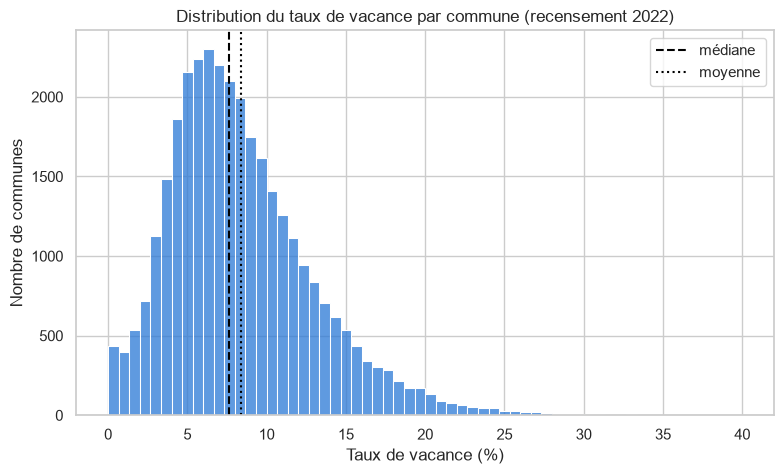

Moyenne : 8.4 % | Médiane : 7.6 %
0.25     5.2
0.75    10.9
0.90    14.5
0.99    22.6
Name: taux_vacance, dtype: float64
Taux national : 8.0 %


In [15]:
plt.figure(figsize=(9, 5))
sns.histplot(com["taux_vacance"], bins=60, color=bleu)
plt.axvline(com["taux_vacance"].median(), color="black", linestyle="--", label="médiane")
plt.axvline(com["taux_vacance"].mean(), color="black", linestyle=":", label="moyenne")
plt.title("Distribution du taux de vacance par commune (recensement 2022)")
plt.xlabel("Taux de vacance (%)")
plt.ylabel("Nombre de communes")
plt.legend()
plt.show()

# Validation : moyenne > médiane = distribution étirée à droite ; quantiles pour situer les extrêmes
print("Moyenne :", round(com["taux_vacance"].mean(), 1), "% | Médiane :", round(com["taux_vacance"].median(), 1), "%")
print(com["taux_vacance"].quantile([0.25, 0.75, 0.9, 0.99]).round(1))
# Taux national (somme des vacants / somme des logements) : point de comparaison
print("Taux national :", round(com["P22_LOGVAC"].sum() / com["P22_LOG"].sum() * 100, 1), "%")

**Interprétation du graphique :** la moitié des communes ont entre 5,2 % et 10,9 % de logements vacants (médiane 7,6 %). La distribution est étirée vers la droite : 10 % des communes dépassent 14,5 % et 1 % dépassent 22,6 %. Ces territoires sont en déprise : centres anciens dégradés, zones rurales du centre de la France, outre-mer. Un pic à 0 % correspond aux petites communes où aucun logement vacant n'a été recensé.

**Choix de la validation :** pour décrire la forme d'une distribution, on compare la moyenne et la médiane (asymétrie) et on lit les quantiles (où se situent les valeurs extrêmes). Le taux national, calculé à partir des sommes de logements, sert de point de comparaison.

**Interprétation de la validation :** la moyenne (8,4 %) dépasse la médiane (7,6 %), ce qui confirme l'asymétrie à droite. Le taux national (8,0 %) est plus bas que la moyenne des communes : dans une moyenne simple, un village très vacant pèse autant qu'une grande ville, alors que les grandes villes, plus peuplées, ont une vacance plus faible.

**Avis métier :** la vacance mesure la tension du marché : faible là où la demande est forte, élevée dans les territoires en déprise où les prix sont bas. Il faut calculer les taux à partir de sommes de logements, jamais par moyenne de taux. Pour les modèles linéaires, cette variable asymétrique gagnera à être transformée (classes ou logarithme).

## Graphique 2 : petits logements selon la taille de la commune

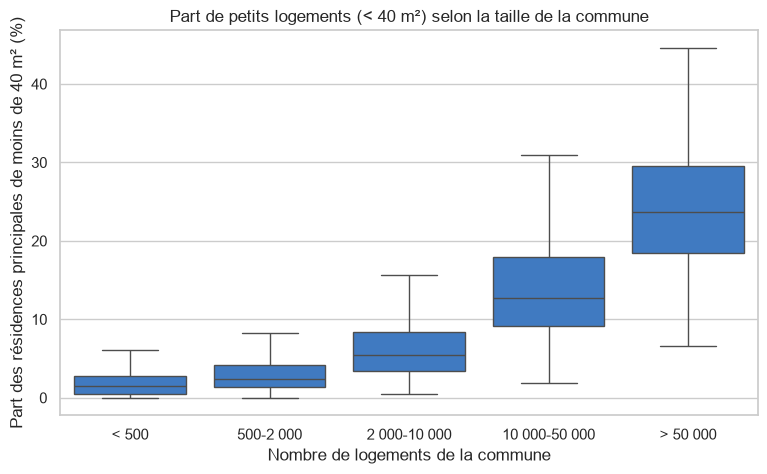

               count  mean  median
taille                            
< 500          22371   2.1     1.5
500-2 000       7488   3.2     2.4
2 000-10 000    2505   6.6     5.5
10 000-50 000    511  14.4    12.7
> 50 000          58  25.1    23.7
F_onewayResult(statistic=np.float64(3672.006923550634), pvalue=np.float64(0.0))
êta² : 0.308


In [16]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=com, x="taille", y="part_moins40m2", color=bleu, showfliers=False)
plt.title("Part de petits logements (< 40 m²) selon la taille de la commune")
plt.xlabel("Nombre de logements de la commune")
plt.ylabel("Part des résidences principales de moins de 40 m² (%)")
plt.show()

# Validation 1 : moyenne et médiane par tranche
print(com.groupby("taille", observed=True)["part_moins40m2"].agg(["count", "mean", "median"]).round(1))

# Validation 2 : ANOVA (5 groupes)
tranches = ["< 500", "500-2 000", "2 000-10 000", "10 000-50 000", "> 50 000"]
groupes = []
for t in tranches:
    groupes.append(com[com["taille"] == t]["part_moins40m2"])
print(stats.f_oneway(groupes[0], groupes[1], groupes[2], groupes[3], groupes[4]))

# Taille d'effet : êta² = part de la variance expliquée par la taille de la commune
moyenne = com["part_moins40m2"].mean()
entre = 0
for g in groupes:
    entre = entre + len(g) * (g.mean() - moyenne) ** 2
total = ((com["part_moins40m2"] - moyenne) ** 2).sum()
print("êta² :", round(entre / total, 3))

**Interprétation du graphique :** la part de petits logements (moins de 40 m²) augmente très nettement avec la taille de la commune. La médiane passe de 1,5 % dans les villages (moins de 500 logements) à 23,7 % dans les grandes villes (plus de 50 000) : une résidence principale sur quatre y est un studio ou un petit deux-pièces, contre presque aucune à la campagne. La dispersion augmente aussi : les communes moyennes sont plus hétérogènes (villes étudiantes contre villes résidentielles).

**Choix du test :** on compare la moyenne d'une variable quantitative entre 5 classes de taille de commune : c'est le cas de l'ANOVA. Avec 32 933 communes, la p-value sera forcément très faible ; l'êta² mesure l'ampleur de l'effet.

**Interprétation du test :** l'ANOVA est très significative (F = 3 672, p ≈ 0). L'êta² vaut 0,308 : la taille de la commune explique 31 % des différences de part de petits logements, un effet **fort** (au-delà du seuil de 0,14).

**Avis métier :** les petites surfaces se concentrent en ville, là où le prix au m² est le plus élevé (un studio se vend plus cher au m² qu'une maison). Ce sont aussi les biens les plus recherchés en location (étudiants, jeunes actifs). Cette variable aidera à corriger l'effet de composition : une ville avec beaucoup de studios aura mécaniquement un prix médian au m² plus élevé.

## Graphique 3 : mobilité résidentielle et marché locatif

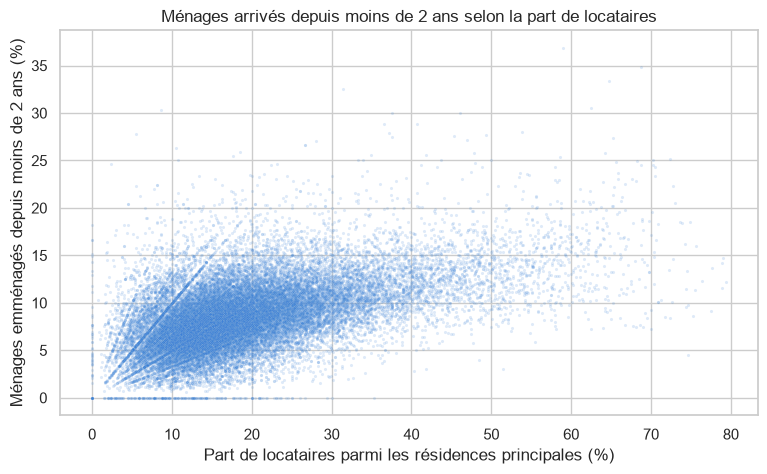

Pearson : PearsonRResult(statistic=np.float64(0.5248130717281949), pvalue=np.float64(0.0))
Spearman : SignificanceResult(statistic=np.float64(0.5169055044010045), pvalue=np.float64(0.0))


In [17]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=com, x="part_locataires", y="part_emmenages_2ans", s=5, alpha=0.15, color=bleu)
plt.title("Ménages arrivés depuis moins de 2 ans selon la part de locataires")
plt.xlabel("Part de locataires parmi les résidences principales (%)")
plt.ylabel("Ménages emménagés depuis moins de 2 ans (%)")
plt.show()

# Validation : corrélations (le coefficient sert aussi de taille d'effet)
print("Pearson :", stats.pearsonr(com["part_locataires"], com["part_emmenages_2ans"]))
print("Spearman :", stats.spearmanr(com["part_locataires"], com["part_emmenages_2ans"]))

**Interprétation du graphique :** plus une commune compte de locataires, plus elle a de ménages arrivés récemment. Autour de 10 % de locataires, 5 à 10 % des ménages ont emménagé depuis moins de 2 ans ; au-delà de 40 % de locataires, on monte souvent à 15-20 %. Le nuage reste large : à part de locataires égale, la mobilité varie beaucoup. Les lignes diagonales et la rangée à 0 % en bas à gauche viennent des toutes petites communes, dont les effectifs (quelques ménages) ne prennent que quelques valeurs possibles.

**Choix du test :** deux variables quantitatives continues : on mesure leur lien avec Pearson (relation linéaire) et Spearman (relation monotone, moins sensible aux valeurs extrêmes). Comparer les deux indique si la relation est linéaire. Le coefficient sert directement de taille d'effet.

**Interprétation du test :** Pearson (r = 0,52) et Spearman (ρ = 0,52) sont presque identiques : la relation est monotone et à peu près linéaire. Au-delà de 0,5, le lien est **fort**. Les p-values sont nulles, ce qui est attendu avec 32 933 communes.

**Avis métier :** le taux d'emménagements récents mesure le dynamisme du marché (rotation des occupants, liquidité). Pour un investisseur, une commune où les locataires changent souvent offre un marché locatif actif, mais aussi un risque de vacance entre deux locataires. Les deux variables étant fortement liées, il faudra probablement n'en garder qu'une dans le modèle.

## Graphique 4 : ménages sans voiture, communes denses ou non

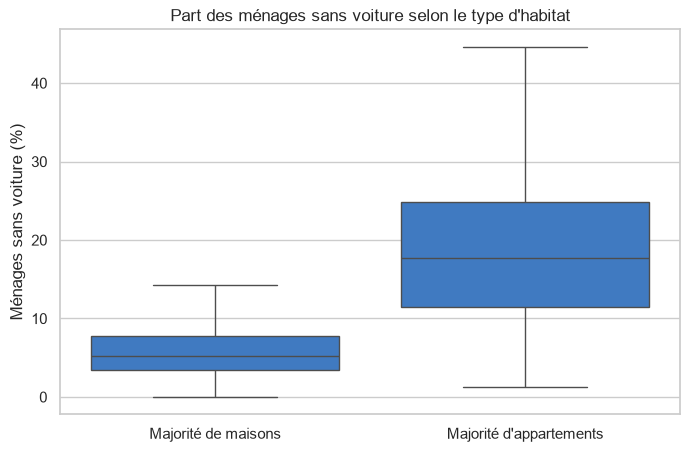

Communes : 1186 denses / 31747 pavillonnaires
Moyennes : 19.8 % / 6.2 %
TtestResult(statistic=np.float64(38.365164631820164), pvalue=np.float64(1.1864506239870515e-210), df=np.float64(1196.9693424191735))
d de Cohen : 1.48


In [18]:
# Commune "dense" : majorité d'appartements
com["habitat"] = np.where(com["part_apparts"] > 50, "Majorité d'appartements", "Majorité de maisons")

plt.figure(figsize=(8, 5))
sns.boxplot(data=com, x="habitat", y="part_sans_voiture", color=bleu, showfliers=False)
plt.title("Part des ménages sans voiture selon le type d'habitat")
plt.xlabel("")
plt.ylabel("Ménages sans voiture (%)")
plt.show()

# Validation : test t de Welch (2 groupes) + taille d'effet (d de Cohen)
dense = com[com["habitat"] == "Majorité d'appartements"]["part_sans_voiture"]
pavillon = com[com["habitat"] == "Majorité de maisons"]["part_sans_voiture"]
print("Communes :", len(dense), "denses /", len(pavillon), "pavillonnaires")
print("Moyennes :", round(dense.mean(), 1), "% /", round(pavillon.mean(), 1), "%")
print(stats.ttest_ind(dense, pavillon, equal_var=False))
ecart_type = np.sqrt((dense.var() + pavillon.var()) / 2)
print("d de Cohen :", round((dense.mean() - pavillon.mean()) / ecart_type, 2))

**Interprétation du graphique :** dans les communes à majorité d'appartements, un ménage sur cinq en moyenne n'a pas de voiture (19,8 %), contre 6,2 % dans les communes à majorité de maisons. Les deux boîtes ne se chevauchent presque pas. Les communes denses ne sont que 1 186 sur 32 933, mais elles regroupent une grande partie de la population.

**Choix du test :** on compare la moyenne d'une variable quantitative entre deux groupes de tailles et de variances très différentes (1 186 contre 31 747 communes) : c'est le cas du test t de Welch (`equal_var=False`). Le d de Cohen mesure l'ampleur de l'écart.

**Interprétation du test :** l'écart est très significatif (t = 38,4 ; p ≈ 10⁻²¹⁰) et surtout **très fort** : d = 1,48, bien au-delà du seuil de 0,8. C'est l'effet le plus net de cette EDA.

**Avis métier :** se passer de voiture n'est possible que là où les transports en commun et les services sont proches. La part de ménages sans voiture est donc une mesure indirecte de l'accessibilité, l'un des facteurs cités dans le sujet (« transports, services »), que le recensement fournit pour toute la France. On s'attend à ce qu'elle soit fortement liée au prix au m², à vérifier après la jointure avec DVF+.

## Graphique 5: corrélations entre indicateurs

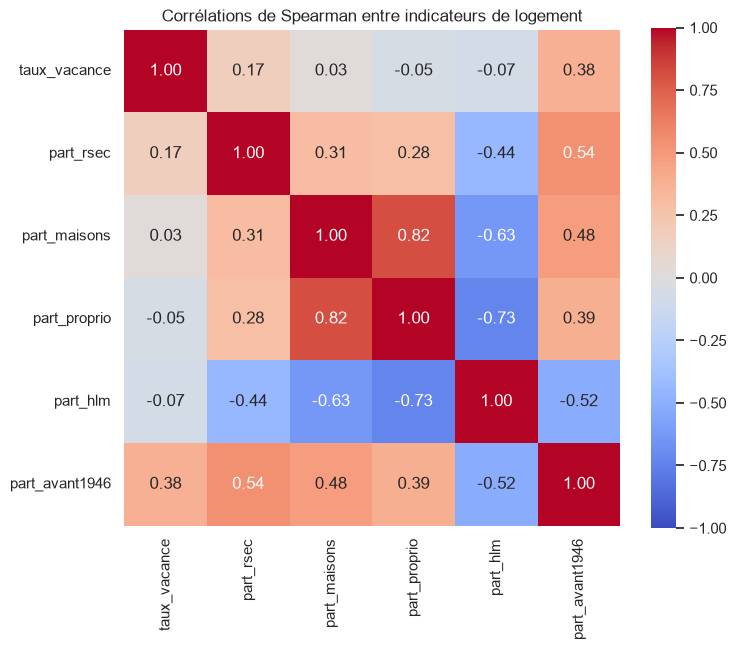

Maisons / propriétaires : SignificanceResult(statistic=np.float64(0.8150857829579694), pvalue=np.float64(0.0))
Propriétaires / HLM : SignificanceResult(statistic=np.float64(-0.7267348676046286), pvalue=np.float64(0.0))
Maisons / HLM : SignificanceResult(statistic=np.float64(-0.6348114607947348), pvalue=np.float64(0.0))


In [13]:
indicateurs = ["taux_vacance", "part_rsec", "part_maisons", "part_proprio", "part_hlm", "part_avant1946"]
correlations = l[indicateurs].corr(method="spearman")

plt.figure(figsize=(8, 6.5))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Corrélations de Spearman entre indicateurs de logement")
plt.show()

# Validation : test des corrélations les plus fortes
print("Maisons / propriétaires :", stats.spearmanr(l["part_maisons"], l["part_proprio"]))
print("Propriétaires / HLM :", stats.spearmanr(l["part_proprio"], l["part_hlm"]))
print("Maisons / HLM :", stats.spearmanr(l["part_maisons"], l["part_hlm"]))


**Interprétation du graphique :** un bloc de variables très liées se détache : part de maisons et de propriétaires (0,82), part de propriétaires et de HLM (-0,73), part de maisons et de HLM (-0,63). Ces trois variables décrivent le même axe : « pavillonnaire / propriétaires » contre « collectif / logement social ». La vacance, elle, est presque indépendante de ce bloc (moins de 0,1 en valeur absolue) : elle apporte une information nouvelle. Son lien le plus net est avec l'ancienneté du parc (0,38).

**Interprétation des tests :** toutes les corrélations testées sont significatives (p ≈ 0), ce qui est attendu avec 46 800 IRIS. Ce qui compte, c'est leur valeur : au-delà de 0,7, les variables sont redondantes.

**Avis métier :** pour la modélisation, ne garder qu'une variable du bloc maisons / propriétaires / HLM (la part de maisons, la plus simple à interpréter, ou la part de HLM pour le profil social). Conserver la vacance, les résidences secondaires et l'ancienneté du parc, qui apportent chacune une information différente.

## Conclusion

**Synthèse de l'EDA :** la base logement décrit à la fois la tension du marché et le gradient urbain, du village à la grande ville, qui structure le marché immobilier. La vacance (médiane 7,6 % par commune) est très inégale et signale les territoires en déprise. La taille des logements (η² = 0,31, effet fort) et l'accessibilité sans voiture (d = 1,48, effet très fort) sont les marqueurs les plus nets du gradient urbain. La mobilité résidentielle est fortement liée au marché locatif (ρ = 0,52) : ces deux variables sont en partie redondantes. Toutes sont de bons candidats pour expliquer les prix au m² ; leur intérêt réel sera mesuré après la jointure avec DVF+.

## Preprocessing

| Étape | Action | Pourquoi (constat de l'exploration) | Résultat attendu |
|---|---|---|---|
| 0. Chemins | Définir le fichier d'entrée (INSEE) et le fichier de sortie (`data/processed/`) | Ne jamais écraser le fichier d'origine | — |
| 1. Chargement | Lire le CSV avec `sep=";"` et les codes `IRIS`, `COM`, `TYP_IRIS`, `LAB_IRIS` en texte | Sinon perte des zéros initiaux (« 01001 » → 1001), codes corses (2A, 2B) mal lus et jointures impossibles | 49 276 lignes × 101 colonnes |
| 2. Colonnes inutiles | Supprimer 17 colonnes : 10 propres à l'outre-mer, 5 de chauffage, `LAB_IRIS`, `TYP_IRIS` | Valeurs manquantes structurelles (98,6 % et 1,4 %) ; `LAB_IRIS` non documenté ; `TYP_IRIS` sans objet après passage à la commune | 49 276 × 84 |
| 3. IRIS vides | Supprimer les IRIS sans aucun logement | 152 IRIS (zones d'activité, parcs) à effectifs tous nuls : aucune information | 152 lignes supprimées |
| 4. Paris, Lyon, Marseille | Garder le code par arrondissement (`COM`) et créer `COM_ENTIERE` (75056, 69123, 13055) | DVF+ code ces villes par arrondissement ; d'autres sources utilisent la commune entière. Garder les deux permet toutes les jointures sans perdre le détail par arrondissement | 992 IRIS à Paris, 185 à Lyon, 393 à Marseille |
| 5. Agrégation | Additionner les effectifs des IRIS par commune (ou arrondissement) avec `groupby(...).sum()` ; compter les IRIS par commune | DVF+ n'a pas de code IRIS : la jointure se fait par commune. On additionne les effectifs, on ne fait jamais la moyenne des taux | 34 955 communes et arrondissements |
| 6. Indicateurs | Créer 19 indicateurs en parts (%) ou en moyennes, avec une division protégée contre les dénominateurs nuls | Les effectifs bruts dépendent de la taille de la commune et ne sont pas comparables | 19 colonnes : vacance, résidences secondaires, maisons, appartements, petits et grands logements, pièces, âge du parc, propriétaires, locataires, HLM, mobilité, taille des ménages, voiture, parking, suroccupation |
| 7. Colonnes d'aide | Ajouter département, signalement Alsace-Moselle, signalement des petites communes (< 50 logements), taille en logarithme, millésime 2022 | L'Alsace-Moselle est absente de DVF+ (exclusion décidée à la jointure) ; taux fragiles dans les petites communes ; taille très asymétrique ; règle de l'année précédente | 5 colonnes ajoutées |
| 8. Contrôles | Vérifier : une ligne par commune, valeurs manquantes, parts comprises entre 0 et 100, statistiques descriptives | S'assurer que le résultat est propre avant de l'enregistrer | Aucun doublon, aucun message « Attention » |
| 9. Enregistrement | Garder les identifiants, les effectifs utiles, les indicateurs et les signalements ; enregistrer dans un **nouveau** fichier | Fichier prêt pour la jointure avec DVF+ ; le fichier INSEE d'origine reste intact | `logement_commune_2022.csv` : 34 955 lignes × 53 colonnes |

In [2]:
import numpy as np
import pandas as pd


# ═══ ÉTAPE 0 : chemins  ═══════════════════════════════════════════
chemin_entree = "../data/base-ic-logement-2022_csv/base-ic-logement-2022.CSV"
chemin_sortie = "../data/processed/logement_commune_processed_2022.csv"


# ═══ ÉTAPE 1 : chargement, codes en texte ════════════════════════════════════
# Les codes sont lus en texte : garde les zéros du début ("01001") et la Corse ("2A004")
codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv(chemin_entree, sep=";", dtype=codes_texte)
print("Chargé :", logement.shape)


# ═══ ÉTAPE 2 : suppression des colonnes inutiles ═════════════════════════════
# 10 variables propres à l'outre-mer (vides en métropole) et 5 de chauffage (vides en outre-mer)
colonnes_dom = ["P22_RP_ELEC", "P22_RP_EAUCH", "P22_RP_BDWC", "P22_RP_CHOS", "P22_RP_CLIM",
                "P22_RP_TTEGOU", "P22_RP_HABFOR", "P22_RP_CASE", "P22_RP_MIBOIS", "P22_RP_MIDUR"]
colonnes_chauffage = ["P22_RP_CGAZV", "P22_RP_CFIOUL", "P22_RP_CELEC", "P22_RP_CGAZB", "P22_RP_CAUT"]
# LAB_IRIS : label de qualité non documenté ; TYP_IRIS n'a plus de sens après passage à la commune
logement = logement.drop(columns=colonnes_dom + colonnes_chauffage + ["LAB_IRIS", "TYP_IRIS"])
print("Après suppression des colonnes :", logement.shape)


# ═══ ÉTAPE 3 : suppression des IRIS sans logement ════════════════════════════
# 152 IRIS (zones d'activité, parcs...) : tous les effectifs à 0, aucune information
avant = len(logement)
logement = logement[logement["P22_LOG"] > 0]
print("IRIS sans logement supprimés :", avant - len(logement))


# ═══ ÉTAPE 4 : deux codes commune pour Paris, Lyon et Marseille ══════════════
# COM : code d'origine, par arrondissement (75101...) -> c'est celui de DVF+
# COM_ENTIERE : commune entière (75056, 69123, 13055), pour les sources qui codent ainsi
logement["COM_ENTIERE"] = logement["COM"]
paris = logement["COM"].str[:3] == "751"
lyon = logement["COM"].str[:4] == "6938"
marseille = logement["COM"].str[:3] == "132"
logement.loc[paris, "COM_ENTIERE"] = "75056"
logement.loc[lyon, "COM_ENTIERE"] = "69123"
logement.loc[marseille, "COM_ENTIERE"] = "13055"
print("IRIS concernés (Paris, Lyon, Marseille) :", paris.sum(), lyon.sum(), marseille.sum())


# ═══ ÉTAPE 5 : agrégation par commune (ou arrondissement) ════════════════════
# On ADDITIONNE les effectifs des IRIS d'une même commune (jamais de moyenne de taux).
# Les variables "totaux" (pièces, personnes, années) s'additionnent aussi.
colonnes_effectifs = []
for c in logement.columns:
    if c.startswith("P22_") or c.startswith("C22_"):
        colonnes_effectifs.append(c)

# groupby sur COM ET COM_ENTIERE : une ligne par commune ou arrondissement,
# et la colonne COM_ENTIERE est conservée dans le résultat
commune = logement.groupby(["COM", "COM_ENTIERE"])[colonnes_effectifs].sum().reset_index()

# Nombre d'IRIS par commune (1 = commune non découpée)
nb_iris = logement.groupby("COM")["IRIS"].count().reset_index()
nb_iris.columns = ["COM", "nb_iris"]
commune = commune.merge(nb_iris, on="COM", how="left")
print("Communes et arrondissements après agrégation :", len(commune))


# ═══ ÉTAPE 6 : création des indicateurs (feature engineering) ════════════════
# Division sûre : renvoie NaN si le dénominateur vaut 0 (au lieu d'une erreur ou de l'infini)
def ratio(numerateur, denominateur):
    return (numerateur / denominateur.replace(0, np.nan)) * 100

c = commune          # nom court
log_ = c["P22_LOG"]  # dénominateur : tous les logements
rp = c["P22_RP"]     # dénominateur : résidences principales
men = c["P22_MEN"]   # dénominateur : ménages

# Marché : vacance et tourisme
c["taux_vacance"] = ratio(c["P22_LOGVAC"], log_)
c["part_rsec"] = ratio(c["P22_RSECOCC"], log_)

# Type d'habitat
c["part_maisons"] = ratio(c["P22_MAISON"], log_)
c["part_apparts"] = ratio(c["P22_APPART"], log_)

# Taille des logements (résidences principales)
c["part_moins40m2"] = ratio(c["P22_RP_M30M2"] + c["P22_RP_3040M2"], rp)
c["part_100m2_plus"] = ratio(c["P22_RP_100120M2"] + c["P22_RP_120M2P"], rp)
c["nb_pieces_moyen"] = c["P22_NBPI_RP"] / rp.replace(0, np.nan)          # moyenne, pas un %

# Âge du parc
c["part_avant1946"] = ratio(c["P22_RP_ACH1919"] + c["P22_RP_ACH1945"], rp)
c["part_2006_2019"] = ratio(c["P22_RP_ACH2019"], rp)

# Profil social / statut d'occupation
c["part_proprio"] = ratio(c["P22_RP_PROP"], rp)
c["part_locataires"] = ratio(c["P22_RP_LOC"], rp)
c["part_hlm"] = ratio(c["P22_RP_LOCHLMV"], rp)

# Mobilité résidentielle
c["part_emmenages_2ans"] = ratio(c["P22_MEN_ANEM0002"], men)
c["anciennete_moyenne"] = c["P22_ANEM_RP"] / rp.replace(0, np.nan)      # en années

# Ménages, voiture, stationnement, suroccupation
c["taille_menage"] = c["P22_NPER_RP"] / rp.replace(0, np.nan)           # personnes par ménage
c["part_sans_voiture"] = 100 - ratio(c["P22_RP_VOIT1P"], men)
c["part_2voitures"] = ratio(c["P22_RP_VOIT2P"], men)
c["part_parking"] = ratio(c["P22_RP_GARL"], men)
c["part_suroccupes"] = ratio(c["C22_RP_SUROCC_MOD"] + c["C22_RP_SUROCC_ACC"], rp)

indicateurs = ["taux_vacance", "part_rsec", "part_maisons", "part_apparts",
               "part_moins40m2", "part_100m2_plus", "nb_pieces_moyen",
               "part_avant1946", "part_2006_2019",
               "part_proprio", "part_locataires", "part_hlm",
               "part_emmenages_2ans", "anciennete_moyenne",
               "taille_menage", "part_sans_voiture", "part_2voitures", "part_parking", "part_suroccupes"]


# ═══ ÉTAPE 7 : colonnes d'aide pour la suite ═════════════════════════════════
# Département (2 caractères en métropole, 3 en outre-mer)
c["dep"] = np.where(c["COM"].str[:2] == "97", c["COM"].str[:3], c["COM"].str[:2])

# Alsace-Moselle : absente de DVF+ -> on la SIGNALE au lieu de la supprimer (choix fait à la jointure)
c["alsace_moselle"] = c["dep"].isin(["57", "67", "68"])

# Fiabilité : en dessous de 50 logements, les taux estimés sont fragiles
c["petite_commune"] = c["P22_LOG"] < 50

# Taille de la commune, en logarithme (distribution très asymétrique)
c["log_nb_logements"] = np.log10(c["P22_LOG"])

# Millésime : utile pour la règle "informations de l'année précédente"
c["annee_rp"] = 2022


# ═══ ÉTAPE 8 : contrôles avant d'enregistrer ═════════════════════════════════
print("Une ligne par commune :", c["COM"].is_unique)
print("Valeurs manquantes par indicateur :")
print(c[indicateurs].isna().sum())
# Les parts doivent être comprises entre 0 et 100
for col in indicateurs:
    if col.startswith("part_") or col == "taux_vacance":
        hors_bornes = ((c[col] < -0.01) | (c[col] > 100.01)).sum()
        if hors_bornes > 0:
            print("Attention :", col, "a", hors_bornes, "valeurs hors de [0, 100]")
print(c[indicateurs].describe().round(1).T)
print("Communes signalées Alsace-Moselle :", c["alsace_moselle"].sum(),
      "| petites communes (< 50 logements) :", c["petite_commune"].sum())


# ═══ ÉTAPE 9 : enregistrement ════════════════════════════════════════════════
# On garde : identifiants, effectifs utiles aux jointures, indicateurs et colonnes d'aide et les 
# effectifs bruts : numérateurs et dénominateurs de tous les indicateurs,
# pour pouvoir recalculer les taux à n'importe quelle échelle dont bassin de vie

effectifs_utiles = ["P22_LOG", "P22_RP", "P22_MEN",
                    "P22_LOGVAC", "P22_RSECOCC", "P22_MAISON", "P22_APPART",
                    "P22_RP_M30M2", "P22_RP_3040M2", "P22_RP_100120M2", "P22_RP_120M2P", "P22_NBPI_RP",
                    "P22_RP_ACH1919", "P22_RP_ACH1945", "P22_RP_ACH2019",
                    "P22_RP_PROP", "P22_RP_LOC", "P22_RP_LOCHLMV",
                    "P22_MEN_ANEM0002", "P22_ANEM_RP", "P22_NPER_RP",
                    "P22_RP_VOIT1P", "P22_RP_VOIT2P", "P22_RP_GARL",
                    "C22_RP_SUROCC_MOD", "C22_RP_SUROCC_ACC"]

colonnes_finales = (["COM", "COM_ENTIERE", "dep", "annee_rp", "nb_iris", "log_nb_logements"]
                    + effectifs_utiles + indicateurs + ["alsace_moselle", "petite_commune"])

resultat = c[colonnes_finales]

# NOUVEAU fichier dans le dossier "processed"  :
# le fichier INSEE d'origine n'est jamais modifié
resultat.to_csv(chemin_sortie, sep=";", index=False)
print("Enregistré :", resultat.shape)

Chargé : (49276, 101)
Après suppression des colonnes : (49276, 84)
IRIS sans logement supprimés : 152
IRIS concernés (Paris, Lyon, Marseille) : 940 181 381
Communes et arrondissements après agrégation : 34955
Une ligne par commune : True
Valeurs manquantes par indicateur :
taux_vacance           0
part_rsec              0
part_maisons           0
part_apparts           0
part_moins40m2         1
part_100m2_plus        1
nb_pieces_moyen        1
part_avant1946         1
part_2006_2019         1
part_proprio           1
part_locataires        1
part_hlm               1
part_emmenages_2ans    1
anciennete_moyenne     1
taille_menage          1
part_sans_voiture      1
part_2voitures         1
part_parking           1
part_suroccupes        1
dtype: int64
                       count  mean   std  min   25%   50%   75%    max
taux_vacance         34955.0   8.5   4.8  0.0   5.2   7.7  11.0  100.0
part_rsec            34955.0  13.1  15.2  0.0   2.7   7.2  17.6   97.2
part_maisons         3495

/var/folders/sj/d_fjzzs564b8zsglssv53y380000gn/T/ipykernel_10742/780707689.py:106: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  c["part_parking"] = ratio(c["P22_RP_GARL"], men)
/var/folders/sj/d_fjzzs564b8zsglssv53y380000gn/T/ipykernel_10742/780707689.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  c["part_suroccupes"] = ratio(c["C22_RP_SUROCC_MOD"] + c["C22_RP_SUROCC_ACC"], rp)
/var/folders/sj/d_fjzzs564b8zsglssv53y380000gn/T/ipykernel_10742/780707689.py:119: PerformanceWarning: DataFrame is highly fragmented.  This is u

Enregistré : (34955, 53)
